Task 01


In [ ]:
!pip install yfinance pyarrow
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [ ]:
from datetime import datetime
import json
import os
print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("YFinance version:", yf.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
YFinance version: 0.2.66


In [ ]:
import requests
import pandas as pd
from io import StringIO
from datetime import datetime
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"
}
response = requests.get(
    url,
    headers=headers,
    timeout=30)
# Check request status
response.raise_for_status()

# Extract tables using Pandas
tables = pd.read_html(StringIO(response.text))

# Find S&P 500 constituents table
sp500 = next(
    table for table in tables
    if "Symbol" in table.columns
)

# Extract company symbols
tickers = sp500["Symbol"].tolist()

# Record retrieval date
retrieval_date = datetime.now().strftime("%Y-%m-%d")

print("Retrieval Date:", retrieval_date)
print("Total companies:", len(tickers))

Retrieval Date: 2026-11-24
Total companies: 503


In [ ]:
#To display the first 10 tickers
print(tickers[:10])

['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [ ]:
yahoo_tickers = [
    ticker.replace(".", "-")
    for ticker in tickers
]

print("Original ticker:", tickers[:10])
print("Yahoo ticker:", yahoo_tickers[:10])

Original ticker: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']
Yahoo ticker: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [ ]:
start_date = "2021-01-01"
end_date = "2025-01-01"

benchmark = "^GSPC"

print("Start Date:", start_date)
print("End Date:", end_date)
print("Benchmark:", benchmark)


Start Date: 2021-01-01
End Date: 2025-01-01
Benchmark: ^GSPC


In [ ]:
# Combine stock tickers and benchmark
all_tickers = yahoo_tickers + [benchmark]

# Store downloaded stock data
stock_data = {}

# Download in batches
batch_size = 50

for i in range(0, len(all_tickers), batch_size):

    batch = all_tickers[i:i + batch_size]

    print(f"Downloading batch {i // batch_size + 1}")

    data = yf.download(
        batch,
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=True,
        progress=False
    )

    if data.empty:
        print("No data returned for this batch")
        continue

    # Separate data for each ticker
    if isinstance(data.columns, pd.MultiIndex):

        for ticker in batch:

            if ticker in data.columns.get_level_values(0):
                stock_data[ticker] = data[ticker].copy()

            elif ticker in data.columns.get_level_values(1):
                stock_data[ticker] = data.xs(
                    ticker,
                    axis=1,
                    level=1
                ).copy()

    else:
        if len(batch) == 1:
            stock_data[batch[0]] = data.copy()

print("Download completed.")
print("Successfully downloaded:", len(stock_data))


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Download completed.
Successfully downloaded: 504


In [ ]:
# Display Apple stock data
print(stock_data["AAPL"].head())

# Display Apple data columns
print("\nAvailable columns:")
print(stock_data["AAPL"].columns.tolist())

# Display S&P 500 benchmark data
print("\nS&P 500 Benchmark:")
print(stock_data["^GSPC"].head())

Price             Open        High         Low       Close   Adj Close  \
Date                                                                     
2021-01-04  133.520004  133.610001  126.760002  129.410004  125.537125   
2021-01-05  128.889999  131.740005  128.429993  131.009995  127.089226   
2021-01-06  127.720001  131.050003  126.379997  126.599998  122.811218   
2021-01-07  128.360001  131.630005  127.860001  130.919998  127.001938   
2021-01-08  132.429993  132.630005  130.229996  132.050003  128.098129   

Price          Volume  Dividends  Stock Splits  
Date                                            
2021-01-04  143301900        0.0           0.0  
2021-01-05   97664900        0.0           0.0  
2021-01-06  155088000        0.0           0.0  
2021-01-07  109578200        0.0           0.0  
2021-01-08  105158200        0.0           0.0  

Available columns:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']

S&P 500 Benchmark:
Price        

In [ ]:
#Identify unsuccessful downloads
failed_tickers = [
    ticker for ticker in all_tickers
    if ticker not in stock_data
    or stock_data[ticker].empty
    or stock_data[ticker]["Adj Close"].dropna().empty
]

# Remove failed tickers so they do not enter later checks
for ticker in failed_tickers:
    stock_data.pop(ticker, None)

downloaded_tickers = list(stock_data.keys())

print("Total requested:", len(all_tickers))
print("Successfully downloaded:", len(downloaded_tickers))
print("Failed downloads:", len(failed_tickers))

print("\nFailed ticker symbols:")
print(failed_tickers)

Total requested: 504
Successfully downloaded: 499
Failed downloads: 5

Failed ticker symbols:
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [ ]:
#Save the downloaded data
# Create project folder
os.makedirs("CRM_Coursework_Data", exist_ok=True)

# Save ticker list
sp500.to_csv(
    "CRM_Coursework_Data/sp500_tickers.csv",
    index=False
)

# Combine downloaded stock data
combined_data = pd.concat(
    stock_data,
    names=["Ticker", "Date"]
)

# Save historical data
combined_data.to_parquet(
    "CRM_Coursework_Data/historical_stock_data.parquet"
)

# Save metadata
metadata = {
    "ticker_retrieval_date": retrieval_date,
    "data_download_date": datetime.now().strftime("%Y-%m-%d"),
    "start_date": start_date,
    "end_date_exclusive": end_date,
    "benchmark": benchmark,
    "data_source": "Yahoo Finance",
    "library": "yfinance",
    "yfinance_version": yf.__version__,
    "requested_tickers": len(all_tickers),
    "successfully_downloaded": len(downloaded_tickers),
    "failed_tickers": failed_tickers
}

with open(
    "CRM_Coursework_Data/download_metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("All available data and metadata saved successfully!")


All available data and metadata saved successfully!


Task 1.2

In [ ]:
# Create output folder
os.makedirs("CRM_Coursework_Data/Task_1_2", exist_ok=True)

# Required columns
required_columns = ["Close", "Adj Close", "Volume"]

# Check downloaded datasets
print("Total downloaded datasets:", len(stock_data))
print("Benchmark available:", "^GSPC" in stock_data)

# Check columns
print("\nApple columns:")
print(stock_data["AAPL"].columns.tolist())

print("\nBenchmark columns:")
print(stock_data["^GSPC"].columns.tolist())

Total downloaded datasets: 499
Benchmark available: True

Apple columns:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']

Benchmark columns:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']


In [ ]:
duplicate_results = []

for ticker, df in stock_data.items():

    duplicate_count = df.index.duplicated().sum()

    duplicate_results.append({
        "Ticker": ticker,
        "Total_Rows": len(df),
        "Duplicate_Dates": duplicate_count
    })

duplicate_report = pd.DataFrame(duplicate_results)

print("Duplicate date report:")
display(duplicate_report.head(20))

print("\nTotal duplicate dates:",
      duplicate_report["Duplicate_Dates"].sum())

duplicate_report.to_csv(
    "CRM_Coursework_Data/Task_1_2/duplicate_report.csv",
    index=False
)

Duplicate date report:


,Ticker,Total_Rows,Duplicate_Dates
0,MMM,1005,0
1,AOS,1005,0
2,ABT,1005,0
3,ABBV,1005,0
4,ACN,1005,0
5,ADBE,1005,0
6,AMD,1005,0
7,AES,1005,0
8,AFL,1005,0
9,A,1005,0



Total duplicate dates: 0


In [ ]:
missing_results = []

for ticker, df in stock_data.items():

    missing_results.append({
        "Ticker": ticker,
        "Missing_Close": df["Close"].isna().sum(),
        "Missing_Adj_Close": df["Adj Close"].isna().sum(),
        "Missing_Volume": df["Volume"].isna().sum(),
        "Total_Missing": df[
            required_columns
        ].isna().sum().sum()
    })

missing_report = pd.DataFrame(missing_results)

display(missing_report.head(20))

print("Total missing values:",
      missing_report["Total_Missing"].sum())

missing_report.to_csv(
    "CRM_Coursework_Data/Task_1_2/missing_values_report.csv",
    index=False
)

,Ticker,Missing_Close,Missing_Adj_Close,Missing_Volume,Total_Missing
0,MMM,0,0,0,0
1,AOS,0,0,0,0
2,ABT,0,0,0,0
3,ABBV,0,0,0,0
4,ACN,0,0,0,0
5,ADBE,0,0,0,0
6,AMD,0,0,0,0
7,AES,0,0,0,0
8,AFL,0,0,0,0
9,A,0,0,0,0


Total missing values: 12558


In [ ]:
price_volume_results = []

for ticker, df in stock_data.items():

    close_errors = (df["Close"].dropna() <= 0).sum()

    adj_close_errors = (df["Adj Close"].dropna() <= 0).sum()

    volume_errors = (df["Volume"].dropna() < 0).sum()

    zero_volume = (df["Volume"] == 0).sum()

    price_volume_results.append({
        "Ticker": ticker,
        "NonPositive_Close": close_errors,
        "NonPositive_Adj_Close": adj_close_errors,
        "Negative_Volume": volume_errors,
        "Zero_Volume": zero_volume
    })

price_volume_report = pd.DataFrame(price_volume_results)

display(price_volume_report.head(20))

print("\nTotal non-positive closing prices:",
      price_volume_report["NonPositive_Close"].sum())

print("Total non-positive adjusted prices:",
      price_volume_report["NonPositive_Adj_Close"].sum())

print("Total negative volume errors:",
      price_volume_report["Negative_Volume"].sum())

print("Total zero-volume days:",
      price_volume_report["Zero_Volume"].sum())

price_volume_report.to_csv(
    "CRM_Coursework_Data/Task_1_2/price_volume_report.csv",
    index=False
)

,Ticker,NonPositive_Close,NonPositive_Adj_Close,Negative_Volume,Zero_Volume
0,MMM,0,0,0,0
1,AOS,0,0,0,0
2,ABT,0,0,0,0
3,ABBV,0,0,0,0
4,ACN,0,0,0,0
5,ADBE,0,0,0,0
6,AMD,0,0,0,0
7,AES,0,0,0,0
8,AFL,0,0,0,0
9,A,0,0,0,0



Total non-positive closing prices: 0
Total non-positive adjusted prices: 0
Total negative volume errors: 0
Total zero-volume days: 452


In [ ]:
history_results = []

for ticker, df in stock_data.items():

    history_results.append({
        "Ticker": ticker,
        "First_Date": df.index.min(),
        "Last_Date": df.index.max(),
        "Total_Observations": len(df)
    })

history_report = pd.DataFrame(history_results)

display(
    history_report.sort_values(
        "Total_Observations"
    ).head(20)
)

print("\nHistorical observation summary:")
print(history_report["Total_Observations"].describe())

history_report.to_csv(
    "CRM_Coursework_Data/Task_1_2/history_report.csv",
    index=False
)

,Ticker,First_Date,Last_Date,Total_Observations
0,MMM,2021-01-04,2024-12-31,1005
1,AOS,2021-01-04,2024-12-31,1005
2,ABT,2021-01-04,2024-12-31,1005
3,ABBV,2021-01-04,2024-12-31,1005
4,ACN,2021-01-04,2024-12-31,1005
5,ADBE,2021-01-04,2024-12-31,1005
6,AMD,2021-01-04,2024-12-31,1005
7,AES,2021-01-04,2024-12-31,1005
8,AFL,2021-01-04,2024-12-31,1005
9,A,2021-01-04,2024-12-31,1005



Historical observation summary:
count     499.0
mean     1005.0
std         0.0
min      1005.0
25%      1005.0
50%      1005.0
75%      1005.0
max      1005.0
Name: Total_Observations, dtype: float64


In [ ]:
corporate_action_results = []

for ticker, df in stock_data.items():

    dividends = (
        df["Dividends"].fillna(0)
        if "Dividends" in df.columns
        else pd.Series(0, index=df.index)
    )

    splits = (
        df["Stock Splits"].fillna(0)
        if "Stock Splits" in df.columns
        else pd.Series(0, index=df.index)
    )

    corporate_action_results.append({
        "Ticker": ticker,
        "Dividend_Events": (dividends != 0).sum(),
        "Stock_Split_Events": (splits != 0).sum(),
        "Total_Dividends": dividends.sum(),
        "Split_Ratios": ", ".join(
            map(str, splits[splits != 0].tolist())
        )
    })

corporate_action_report = pd.DataFrame(
    corporate_action_results
)

display(corporate_action_report.head(20))

corporate_action_report.to_csv(
    "CRM_Coursework_Data/Task_1_2/corporate_action_report.csv",
    index=False
)

,Ticker,Dividend_Events,Stock_Split_Events,Total_Dividends,Split_Ratios
0,MMM,16,1,18.312374,1.196
1,AOS,16,0,4.720000,
2,ABT,16,0,7.920000,
3,ABBV,16,0,22.960000,
4,ACN,16,0,17.640000,
5,ADBE,0,0,0.000000,
6,AMD,0,0,0.000000,
7,AES,16,0,2.592000,
8,AFL,16,0,6.600000,
9,A,17,0,3.708000,


In [ ]:
# Extract benchmark adjusted closing prices

benchmark_df = stock_data["^GSPC"]

benchmark_prices = benchmark_df["Adj Close"].dropna()

# Friday-ending weekly prices
benchmark_weekly = benchmark_prices.resample(
    "W-FRI"
).last()

# Calculate benchmark weekly returns
benchmark_returns = benchmark_weekly.pct_change()

# Store weekly returns for all stocks
weekly_returns = {}

for ticker, df in stock_data.items():

    if ticker == "^GSPC":
        continue

    adjusted_prices = df["Adj Close"].dropna()

    # Friday-ending weekly adjusted prices
    weekly_prices = adjusted_prices.resample(
        "W-FRI"
    ).last()

    # Calculate weekly returns
    stock_weekly_returns = weekly_prices.pct_change()

    # Align stock and benchmark on identical week labels
    aligned = pd.concat(
        [
            stock_weekly_returns.rename("Stock_Return"),
            benchmark_returns.rename("Benchmark_Return")
        ],
        axis=1,
        join="inner"
    )

    # Remove weeks where either return is missing
    aligned = aligned.dropna()

    weekly_returns[ticker] = aligned

print("Weekly resampling completed.")

print("Apple aligned weekly returns:")
display(weekly_returns["AAPL"].head())

print("\nNumber of Apple aligned observations:",
      len(weekly_returns["AAPL"]))

Weekly resampling completed.
Apple aligned weekly returns:


,Stock_Return,Benchmark_Return
Date,,
2021-01-15,-0.037183,-0.014754
2021-01-22,0.093834,0.019431
2021-01-29,-0.051126,-0.033120
2021-02-05,0.037923,0.046467
2021-02-12,-0.010164,0.012349



Number of Apple aligned observations: 208


In [ ]:
final_validation = []

valid_daily = {}

for ticker, df in stock_data.items():

    reasons = []

    # Check required columns
    if not all(col in df.columns for col in required_columns):

        reasons.append("Missing required columns")

    else:

        # Check duplicate dates
        if df.index.duplicated().any():
            reasons.append("Duplicate dates")

        # Check invalid prices and volume
        if (df["Close"].dropna() <= 0).any():
            reasons.append("Non-positive Close prices")

        if (df["Adj Close"].dropna() <= 0).any():
            reasons.append("Non-positive Adjusted Close prices")

        if (df["Volume"].dropna() < 0).any():
            reasons.append("Negative volume")

        # Identify valid observations without filling missing data
        valid_mask = (
            df[required_columns].notna().all(axis=1)
            & (df["Close"] > 0)
            & (df["Adj Close"] > 0)
            & (df["Volume"] >= 0)
        )

        clean_df = df.loc[valid_mask].copy()

        if len(clean_df) < 500:
            reasons.append("Insufficient valid daily history")

        if not reasons:
            valid_daily[ticker] = clean_df

    final_validation.append({
        "Ticker": ticker,
        "Original_Rows": len(df),
        "Valid_Rows": len(valid_daily.get(ticker, [])),
        "Status": "Included" if not reasons else "Excluded",
        "Reason": "; ".join(reasons) if reasons else "Passed"
    })

validation_report = pd.DataFrame(final_validation)

display(validation_report.head(20))

print("\nIncluded datasets:",
      (validation_report["Status"] == "Included").sum())

print("Excluded datasets:",
      (validation_report["Status"] == "Excluded").sum())

validation_report.to_csv(
    "CRM_Coursework_Data/Task_1_2/final_validation_report.csv",
    index=False
)

,Ticker,Original_Rows,Valid_Rows,Status,Reason
0,MMM,1005,1005,Included,Passed
1,AOS,1005,1005,Included,Passed
2,ABT,1005,1005,Included,Passed
3,ABBV,1005,1005,Included,Passed
4,ACN,1005,1005,Included,Passed
5,ADBE,1005,1005,Included,Passed
6,AMD,1005,1005,Included,Passed
7,AES,1005,1005,Included,Passed
8,AFL,1005,1005,Included,Passed
9,A,1005,1005,Included,Passed



Included datasets: 495
Excluded datasets: 4


In [ ]:
weekly_output = pd.concat(
    weekly_returns,
    names=["Ticker", "Week"]
)

weekly_output.to_csv(
    "CRM_Coursework_Data/Task_1_2/weekly_aligned_returns.csv"
)

print("Weekly aligned returns saved successfully!")

Weekly aligned returns saved successfully!


Task 1.3

In [ ]:
# Task 1.3 output folder
TASK_13_DIR = "CRM_Coursework_Data/Task_1_3"
os.makedirs(TASK_13_DIR, exist_ok=True)

# Study period
start_ts = pd.Timestamp(start_date)
end_ts = pd.Timestamp(end_date)  # Exclusive

BENCHMARK_TICKER = "^GSPC"

# Last date included in the study period
end_inclusive = end_ts - pd.Timedelta(days=1)

print("Study start:", start_ts.date())
print("Study end:", end_inclusive.date())
print("Benchmark:", BENCHMARK_TICKER)
print("Validated shares available:", len(valid_daily))

Study start: 2021-01-01
Study end: 2024-12-31
Benchmark: ^GSPC
Validated shares available: 495


In [ ]:
# Check that benchmark data exists
if BENCHMARK_TICKER not in stock_data:
    raise ValueError("S&P 500 benchmark data is missing.")

# Get adjusted closing prices safely
def get_adjusted_close(df, ticker):

    if "Adj Close" not in df.columns:
        raise ValueError(f"{ticker}: Adjusted Close is unavailable.")

    prices = df["Adj Close"].copy()

    prices.index = pd.to_datetime(prices.index)

    # Remove timezone information if present
    if prices.index.tz is not None:
        prices.index = prices.index.tz_localize(None)

    if prices.index.has_duplicates:
        raise ValueError(f"{ticker}: Duplicate dates must be resolved in Task 1.2.")

    prices = prices.sort_index()

    # Restrict to the required study period
    prices = prices.loc[
        (prices.index >= start_ts) &
        (prices.index < end_ts)
    ]

    # Treat nonpositive prices as invalid
    prices = prices.where(prices > 0)

    return prices


# Benchmark adjusted closing prices
benchmark_prices = get_adjusted_close(
    stock_data[BENCHMARK_TICKER],
    BENCHMARK_TICKER
)

# Create Friday-ending weekly prices
benchmark_weekly_prices = benchmark_prices.resample("W-FRI").last()

# Identify complete calendar weeks only
# A complete week must start on or after the study start
# and finish on or before the study end.
full_week_labels = pd.date_range(
    start=start_ts + pd.Timedelta(days=4),
    end=end_inclusive,
    freq="W-FRI"
)

benchmark_weekly_prices = benchmark_weekly_prices.reindex(
    full_week_labels
)

print("Number of complete weekly labels:", len(full_week_labels))
print("\nBenchmark weekly prices:")
display(benchmark_weekly_prices.head())

Number of complete weekly labels: 208

Benchmark weekly prices:


,Adj Close
2021-01-08,3824.679932
2021-01-15,3768.250000
2021-01-22,3841.469971
2021-01-29,3714.239990
2021-02-05,3886.830078


In [ ]:
# Calculate S&P 500 weekly returns
benchmark_weekly_returns = benchmark_weekly_prices.pct_change(
    fill_method=None
)

print("S&P 500 weekly returns:")
display(benchmark_weekly_returns.head(10))

# Store benchmark returns
benchmark_weekly_returns.rename(
    "Benchmark_Return"
).to_csv(
    f"{TASK_13_DIR}/benchmark_weekly_returns.csv"
)


S&P 500 weekly returns:


,Adj Close
2021-01-08,NaN
2021-01-15,-0.014754
2021-01-22,0.019431
2021-01-29,-0.033120
2021-02-05,0.046467
2021-02-12,0.012349
2021-02-19,-0.007146
2021-02-26,-0.024460
2021-03-05,0.008079
2021-03-12,0.026393


In [ ]:
weekly_returns = {}
weekly_prices = {}

for ticker, df in valid_daily.items():

    # Do not treat the benchmark as an individual share
    if ticker == BENCHMARK_TICKER:
        continue

    # Get adjusted closing prices
    adjusted_prices = get_adjusted_close(df, ticker)

    # Resample into Friday-ending weeks
    stock_weekly_prices = adjusted_prices.resample("W-FRI").last()

    # Keep the same complete weekly labels as the benchmark
    stock_weekly_prices = stock_weekly_prices.reindex(
        full_week_labels
    )

    # Calculate weekly returns
    stock_weekly_returns = stock_weekly_prices.pct_change(
        fill_method=None
    )

    # Align share and benchmark returns
    aligned_returns = pd.concat(
        [
            stock_weekly_returns.rename("Share_Return"),
            benchmark_weekly_returns.rename("Benchmark_Return")
        ],
        axis=1
    )

    # Keep only weeks with both returns available
    aligned_returns = aligned_returns.dropna()

    weekly_prices[ticker] = stock_weekly_prices
    weekly_returns[ticker] = aligned_returns

print("Shares processed:", len(weekly_returns))

# Display an example
if weekly_returns:
    example_ticker = next(iter(weekly_returns))

    print("Example ticker:", example_ticker)
    display(weekly_returns[example_ticker].head())

Shares processed: 494
Example ticker: MMM


,Share_Return,Benchmark_Return
2021-01-15,-0.006422,-0.014754
2021-01-22,0.021081,0.019431
2021-01-29,0.039162,-0.033120
2021-02-05,0.019071,0.046467
2021-02-12,0.006494,0.012349


In [ ]:
risk_results = []

for ticker, aligned in weekly_returns.items():

    # Number of matched weekly observations
    observation_count = len(aligned)

    if observation_count < 2:
        print("Insufficient observations:", ticker)
        continue

    share_returns = aligned["Share_Return"]
    market_returns = aligned["Benchmark_Return"]

    # Arithmetic mean weekly return
    mean_weekly_return = share_returns.mean()

    # Weekly beta
    benchmark_variance = market_returns.var()

    if pd.isna(benchmark_variance) or benchmark_variance == 0:
        print("Invalid benchmark variance:", ticker)
        continue

    weekly_beta = (
        share_returns.cov(market_returns) /
        benchmark_variance
    )

    risk_results.append({
        "Ticker": ticker,
        "MeanWeeklyReturn": mean_weekly_return,
        "WeeklyBeta": weekly_beta,
        "AlignedWeeklyObservations": observation_count
    })

# Create final feature table
risk_features = pd.DataFrame(risk_results)

if not risk_features.empty:
    risk_features = risk_features.set_index("Ticker").sort_index()

print("Number of shares with calculated features:", len(risk_features))

display(risk_features.head(10))


Number of shares with calculated features: 494


,MeanWeeklyReturn,WeeklyBeta,AlignedWeeklyObservations
Ticker,,,
A,0.001121,1.074724,207
AAPL,0.003930,1.174836,207
ABBV,0.003749,0.425366,207
ABNB,0.001475,1.472709,207
ABT,0.000971,0.583543,207
ACGL,0.005289,0.586638,207
ACN,0.002376,1.143300,207
ADBE,0.000990,1.553525,207
ADI,0.002610,1.131968,207


In [ ]:
# Check the calculated feature table
print("Missing values:")
print(risk_features.isna().sum())

print("\nSummary statistics:")
display(risk_features.describe())

print("\nWeekly observation count:")
display(
    risk_features["AlignedWeeklyObservations"].describe()
)

# Save feature table
risk_features.to_csv(
    f"{TASK_13_DIR}/weekly_return_beta_features.csv"
)

# Save all aligned weekly returns
if weekly_returns:

    aligned_returns_output = pd.concat(
        weekly_returns,
        names=["Ticker", "Week"]
    )

    aligned_returns_output.to_csv(
        f"{TASK_13_DIR}/all_aligned_weekly_returns.csv"
    )

# Save weekly adjusted prices
if weekly_prices:

    weekly_prices_output = pd.DataFrame(weekly_prices)

    weekly_prices_output.to_csv(
        f"{TASK_13_DIR}/weekly_adjusted_prices.csv"
    )

print("\nTask 1.3 calculations completed.")
print("Files saved in:", TASK_13_DIR)

Missing values:
MeanWeeklyReturn             0
WeeklyBeta                   0
AlignedWeeklyObservations    0
dtype: int64

Summary statistics:


,MeanWeeklyReturn,WeeklyBeta,AlignedWeeklyObservations
count,494.000000,494.000000,494.000000
mean,0.002921,0.982578,206.560729
std,0.002728,0.421252,5.381902
min,-0.004468,0.055453,106.000000
25%,0.001216,0.671473,207.000000
50%,0.002675,0.954711,207.000000
75%,0.004272,1.181036,207.000000
max,0.017772,3.778560,207.000000



Weekly observation count:


,AlignedWeeklyObservations
count,494.000000
mean,206.560729
std,5.381902
min,106.000000
25%,207.000000
50%,207.000000
75%,207.000000
max,207.000000



Task 1.3 calculations completed.
Files saved in: CRM_Coursework_Data/Task_1_3


In [ ]:
study_end_date = pd.Timestamp("2024-12-31")
HIGH_WINDOW = 252

rfm_results = []

for ticker, df in valid_daily.items():

    if ticker == BENCHMARK_TICKER:
        continue

    data = df.copy()
    data.index = pd.to_datetime(data.index)
    if data.index.tz is not None:
        data.index = data.index.tz_localize(None)
    data = data.sort_index()
    data = data.loc[(data.index >= start_ts) & (data.index < end_ts)]

    adj_close = data["Adj Close"]

    # Recency: last day the adjusted close set a new rolling 52-week high
    rolling_high = adj_close.rolling(HIGH_WINDOW, min_periods=1).max()
    new_high_days = adj_close.index[adj_close >= rolling_high]
    last_high = new_high_days.max()
    recency_days = (study_end_date - last_high).days

    # Frequency: positive weekly returns (aligned weeks from Task 1.3)
    if ticker in weekly_returns:
        frequency = int((weekly_returns[ticker]["Share_Return"] > 0).sum())
    else:
        frequency = 0

    # Monetary: average daily dollar trading value
    monetary_usd = (data["Close"] * data["Volume"]).mean()

    rfm_results.append({
        "Ticker": ticker,
        "RecencyDays": recency_days,
        "Frequency": frequency,
        "MonetaryUSD": monetary_usd
    })

rfm_features = pd.DataFrame(rfm_results).set_index("Ticker").sort_index()

print("RFM features calculated for", len(rfm_features), "shares.")
display(rfm_features.head())

print("\nSummary statistics:")
display(rfm_features.describe())

rfm_features.to_csv(f"{TASK_13_DIR}/rfm_features.csv")

RFM features calculated for 494 shares.


,RecencyDays,Frequency,MonetaryUSD
Ticker,,,
A,225,99,2.314136e+08
AAPL,5,115,1.203629e+10
ABBV,61,120,8.804027e+08
ABNB,285,108,8.217682e+08
ABT,74,106,6.054450e+08



Summary statistics:


,RecencyDays,Frequency,MonetaryUSD
count,494.000000,494.000000,4.940000e+02
mean,146.101215,109.514170,5.455456e+08
std,227.869010,7.413518,1.611533e+09
min,0.000000,58.000000,1.577200e+07
25%,32.000000,105.000000,1.393105e+08
50%,50.000000,110.000000,2.403825e+08
75%,168.000000,114.000000,4.514290e+08
max,1380.000000,129.000000,2.366024e+10


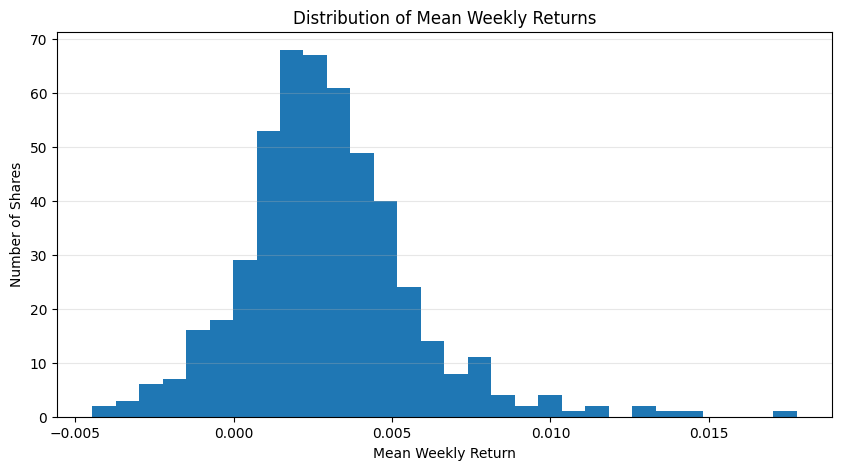

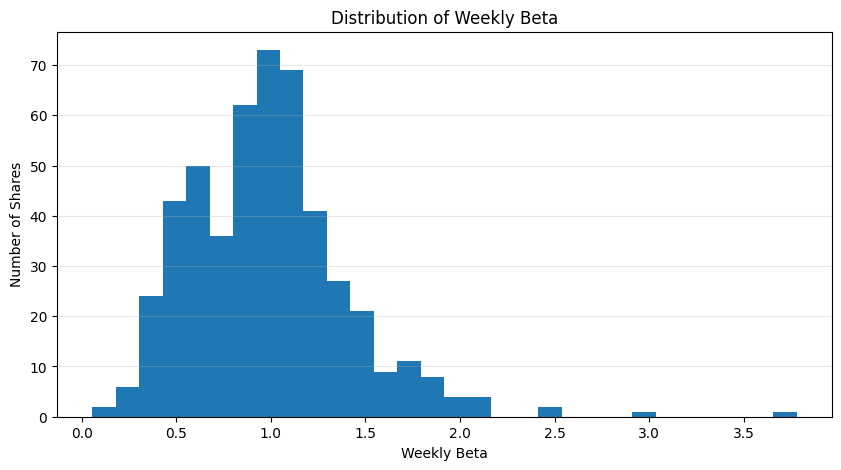

In [ ]:
import matplotlib.pyplot as plt

# Mean weekly return distribution
plt.figure(figsize=(10, 5))

plt.hist(
    risk_features["MeanWeeklyReturn"].dropna(),
    bins=30
)

plt.title("Distribution of Mean Weekly Returns")
plt.xlabel("Mean Weekly Return")
plt.ylabel("Number of Shares")
plt.grid(axis="y", alpha=0.3)
plt.show()


# Weekly beta distribution
plt.figure(figsize=(10, 5))

plt.hist(
    risk_features["WeeklyBeta"].dropna(),
    bins=30
)

plt.title("Distribution of Weekly Beta")
plt.xlabel("Weekly Beta")
plt.ylabel("Number of Shares")
plt.grid(axis="y", alpha=0.3)
plt.show()

Task 02

Task 2.1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import StandardScaler

# Create output folder
TASK_21_DIR = "CRM_Coursework_Data/Task_2_1"
os.makedirs(TASK_21_DIR, exist_ok=True)

print("Libraries ready.")

Libraries ready.


In [ ]:
# Check required columns
risk_columns = [
    "MeanWeeklyReturn",
    "WeeklyBeta"
]

rfm_columns = [
    "RecencyDays",
    "Frequency",
    "MonetaryUSD"
]

print("Risk features available:")
print(risk_features.columns.tolist())

print("\nRFM features available:")
print(rfm_features.columns.tolist())

# Check required columns exist
assert all(col in risk_features.columns for col in risk_columns)
assert all(col in rfm_features.columns for col in rfm_columns)

# Find shares available in both datasets
common_shares = (
    risk_features.index
    .intersection(rfm_features.index)
)

# Create risk and return matrix
risk_matrix = risk_features.loc[
    common_shares, risk_columns
].copy()

# Create original RFM matrix
rfm_matrix_original = rfm_features.loc[
    common_shares, rfm_columns
].copy()

print("\nCommon shares:", len(common_shares))

print("\nRisk and Return Matrix:")
display(risk_matrix.head())

print("\nOriginal RFM Matrix:")
display(rfm_matrix_original.head())


Risk features available:
['MeanWeeklyReturn', 'WeeklyBeta', 'AlignedWeeklyObservations']

RFM features available:
['RecencyDays', 'Frequency', 'MonetaryUSD']

Common shares: 494

Risk and Return Matrix:


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
A,0.001121,1.074724
AAPL,0.003930,1.174836
ABBV,0.003749,0.425366
ABNB,0.001475,1.472709
ABT,0.000971,0.583543



Original RFM Matrix:


,RecencyDays,Frequency,MonetaryUSD
Ticker,,,
A,225,99,2.314136e+08
AAPL,5,115,1.203629e+10
ABBV,61,120,8.804027e+08
ABNB,285,108,8.217682e+08
ABT,74,106,6.054450e+08


In [ ]:
# Check missing values
print("Missing values in Risk Matrix:")
display(risk_matrix.isna().sum())

print("\nMissing values in RFM Matrix:")
display(rfm_matrix_original.isna().sum())

# Check infinite values
print("\nInfinite values in Risk Matrix:")
print(np.isinf(risk_matrix.to_numpy()).sum())

print("\nInfinite values in RFM Matrix:")
print(np.isinf(rfm_matrix_original.to_numpy()).sum())

# Check invalid Monetary values for log1p
print(
    "\nMonetary values less than or equal to -1:",
    (rfm_matrix_original["MonetaryUSD"] <= -1).sum()
)

Missing values in Risk Matrix:


,0
MeanWeeklyReturn,0
WeeklyBeta,0



Missing values in RFM Matrix:


,0
RecencyDays,0
Frequency,0
MonetaryUSD,0



Infinite values in Risk Matrix:
0

Infinite values in RFM Matrix:
0

Monetary values less than or equal to -1: 0


In [ ]:
# Check Monetary values
if (rfm_matrix_original[["RecencyDays", "MonetaryUSD"]] < 0).any().any():
    raise ValueError("Negative Monetary values found. Investigate before transformation.")

# Create transformed RFM matrix
rfm_matrix = rfm_matrix_original.copy()

rfm_matrix["Log1pMonetary"] = np.log1p(
    rfm_matrix["MonetaryUSD"]
)

# Recency is also strongly right-skewed (a few shares have not made a
# new 52-week high for years), so it is log-transformed as well
rfm_matrix["Log1pRecency"] = np.log1p(
    rfm_matrix["RecencyDays"]
)

# Keep the transformed Recency and Monetary features
rfm_matrix = rfm_matrix[
    ["Log1pRecency", "Frequency", "Log1pMonetary"]
]

print("Transformed RFM Matrix:")
display(rfm_matrix.head())


Transformed RFM Matrix:


,Log1pRecency,Frequency,Log1pMonetary
Ticker,,,
A,5.420535,99,19.259717
AAPL,1.791759,115,23.211192
ABBV,4.127134,120,20.595890
ABNB,5.655992,108,20.526969
ABT,4.317488,106,20.221474


In [ ]:
# Calculate skewness before and after transformation
skew_diagnostics = pd.DataFrame({
    "Risk_Return_Skew": risk_matrix.skew(),
    "RFM_Original_Skew": rfm_matrix_original.skew(),
    "RFM_Transformed_Skew": rfm_matrix.skew()
})

print("Skewness Analysis:")
display(skew_diagnostics)

# Save results
skew_diagnostics.to_csv(
    f"{TASK_21_DIR}/skewness_diagnostics.csv"
)


Skewness Analysis:


,Risk_Return_Skew,RFM_Original_Skew,RFM_Transformed_Skew
Frequency,NaN,-0.831315,-0.831315
Log1pMonetary,NaN,NaN,0.957553
Log1pRecency,NaN,NaN,0.529144
MeanWeeklyReturn,0.972831,NaN,NaN
MonetaryUSD,NaN,10.163390,NaN
RecencyDays,NaN,2.922726,NaN
WeeklyBeta,1.248550,NaN,NaN


In [ ]:
def outlier_analysis(data):

    results = []

    for column in data.columns:

        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        outliers = (
            (data[column] < lower_limit) |
            (data[column] > upper_limit)
        )

        results.append({
            "Feature": column,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Limit": lower_limit,
            "Upper_Limit": upper_limit,
            "Outlier_Count": int(outliers.sum()),
            "Outlier_Percentage": outliers.mean() * 100
        })

    return pd.DataFrame(results)


# Analyse both matrices
risk_outliers = outlier_analysis(risk_matrix)
rfm_outliers = outlier_analysis(rfm_matrix)

print("Risk and Return Outlier Analysis:")
display(risk_outliers)

print("\nRFM Outlier Analysis:")
display(rfm_outliers)

# Save reports
risk_outliers.to_csv(
    f"{TASK_21_DIR}/risk_outlier_analysis.csv",
    index=False
)

rfm_outliers.to_csv(
    f"{TASK_21_DIR}/rfm_outlier_analysis.csv",
    index=False
)


Risk and Return Outlier Analysis:


,Feature,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percentage
0,MeanWeeklyReturn,0.001216,0.004272,0.003056,-0.003368,0.008856,17,3.441296
1,WeeklyBeta,0.671473,1.181036,0.509563,-0.092872,1.945381,12,2.429150



RFM Outlier Analysis:


,Feature,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percentage
0,Log1pRecency,3.496508,5.129899,1.633391,1.046421,7.579985,1,0.202429
1,Frequency,105.000000,114.000000,9.000000,91.500000,127.500000,8,1.619433
2,Log1pMonetary,18.752216,19.927929,1.175713,16.988646,21.691498,11,2.226721


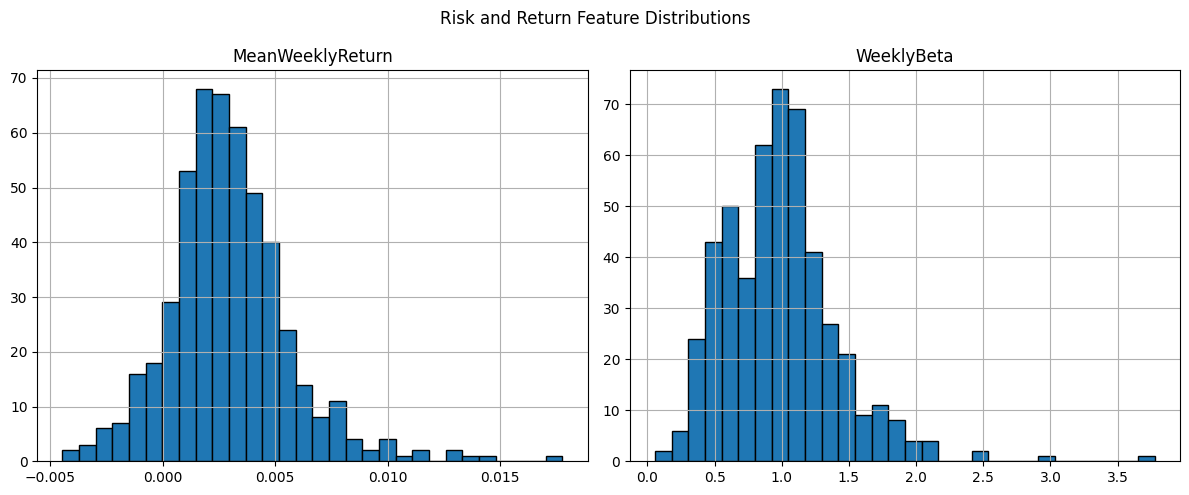

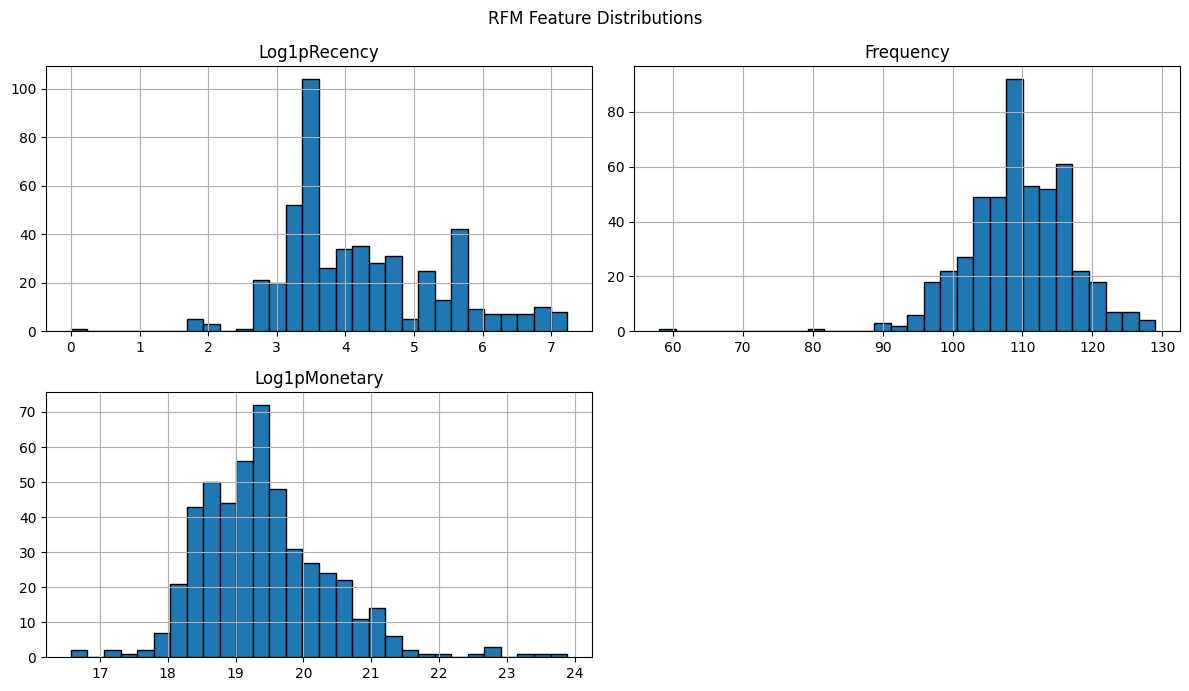

In [ ]:
# Risk and return distributions
risk_matrix.hist(
    figsize=(12, 5),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Risk and Return Feature Distributions")
plt.tight_layout()
plt.show()


# RFM distributions after Monetary transformation
rfm_matrix.hist(
    figsize=(12, 7),
    bins=30,
    edgecolor="black"
)

plt.suptitle("RFM Feature Distributions")
plt.tight_layout()
plt.show()

In [ ]:
# Check all data is valid before scaling
if not np.isfinite(risk_matrix.to_numpy()).all():
    raise ValueError("Risk matrix contains missing or infinite values.")

if not np.isfinite(rfm_matrix.to_numpy()).all():
    raise ValueError("RFM matrix contains missing or infinite values.")

# Create separate scalers
risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

# Fit and transform risk and return features
X_risk = risk_scaler.fit_transform(risk_matrix)

# Fit and transform RFM features
X_rfm = rfm_scaler.fit_transform(rfm_matrix)

print("Risk matrix standardised:", X_risk.shape)
print("RFM matrix standardised:", X_rfm.shape)

Risk matrix standardised: (494, 2)
RFM matrix standardised: (494, 3)


In [ ]:
# Convert scaled arrays back into DataFrames
risk_standardised = pd.DataFrame(
    X_risk,
    index=common_shares,
    columns=risk_matrix.columns
)

rfm_standardised = pd.DataFrame(
    X_rfm,
    index=common_shares,
    columns=rfm_matrix.columns
)

print("Risk matrix - standardised:")
display(risk_standardised.head())

print("\nRFM matrix - standardised:")
display(rfm_standardised.head())

print("\nRisk means:")
display(risk_standardised.mean())

print("\nRisk standard deviations:")
display(risk_standardised.std(ddof=0))

print("\nRFM means:")
display(rfm_standardised.mean())

print("\nRFM standard deviations:")
display(rfm_standardised.std(ddof=0))

Risk matrix - standardised:


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
A,-0.660744,0.218964
AAPL,0.369949,0.456859
ABBV,0.303673,-1.324094
ABNB,-0.530545,1.164689
ABT,-0.715512,-0.948222



RFM matrix - standardised:


,Log1pRecency,Frequency,Log1pMonetary
Ticker,,,
A,1.019912,-1.419681,-0.168178
AAPL,-2.161185,0.740727,3.982930
ABBV,-0.113923,1.415854,1.235500
ABNB,1.226321,-0.204452,1.163097
ABT,0.052947,-0.474502,0.842168



Risk means:


,0
MeanWeeklyReturn,1.222594e-16
WeeklyBeta,-2.337312e-17


... (2 outputs left out)


RFM means:


,0
Log1pRecency,1.008640e-15
Frequency,-9.529040e-16
Log1pMonetary,-1.082355e-15



RFM standard deviations:


,0
Log1pRecency,1.0
Frequency,1.0
Log1pMonetary,1.0


In [ ]:
# Save original feature matrices
risk_matrix.to_csv(
    f"{TASK_21_DIR}/risk_return_matrix.csv"
)

rfm_matrix_original.to_csv(
    f"{TASK_21_DIR}/rfm_original_matrix.csv"
)

# Save transformed RFM matrix
rfm_matrix.to_csv(
    f"{TASK_21_DIR}/rfm_log1p_matrix.csv"
)

# Save standardised matrices
risk_standardised.to_csv(
    f"{TASK_21_DIR}/risk_return_standardised.csv"
)

rfm_standardised.to_csv(
    f"{TASK_21_DIR}/rfm_standardised.csv"
)

# Save common share list
pd.Series(
    common_shares,
    name="Ticker"
).to_csv(
    f"{TASK_21_DIR}/common_shares.csv",
    index=False
)

print("Task 2.1 completed successfully.")
print("Total common shares:", len(common_shares))
print("Files saved in:", TASK_21_DIR)

Task 2.1 completed successfully.
Total common shares: 494
Files saved in: CRM_Coursework_Data/Task_2_1


Task 2.2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

OUTDIR = "coursework_outputs"
os.makedirs(OUTDIR, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
required_variables = ["risk_standardised", "rfm_standardised"]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Complete Task 2.1 first."
        )

print("Risk scaled shape:", risk_standardised.shape)
print("RFM scaled shape:", rfm_standardised.shape)

print(
    "Same share index:",
    risk_standardised.index.equals(rfm_standardised.index)
)

Risk scaled shape: (494, 2)
RFM scaled shape: (494, 3)
Same share index: True


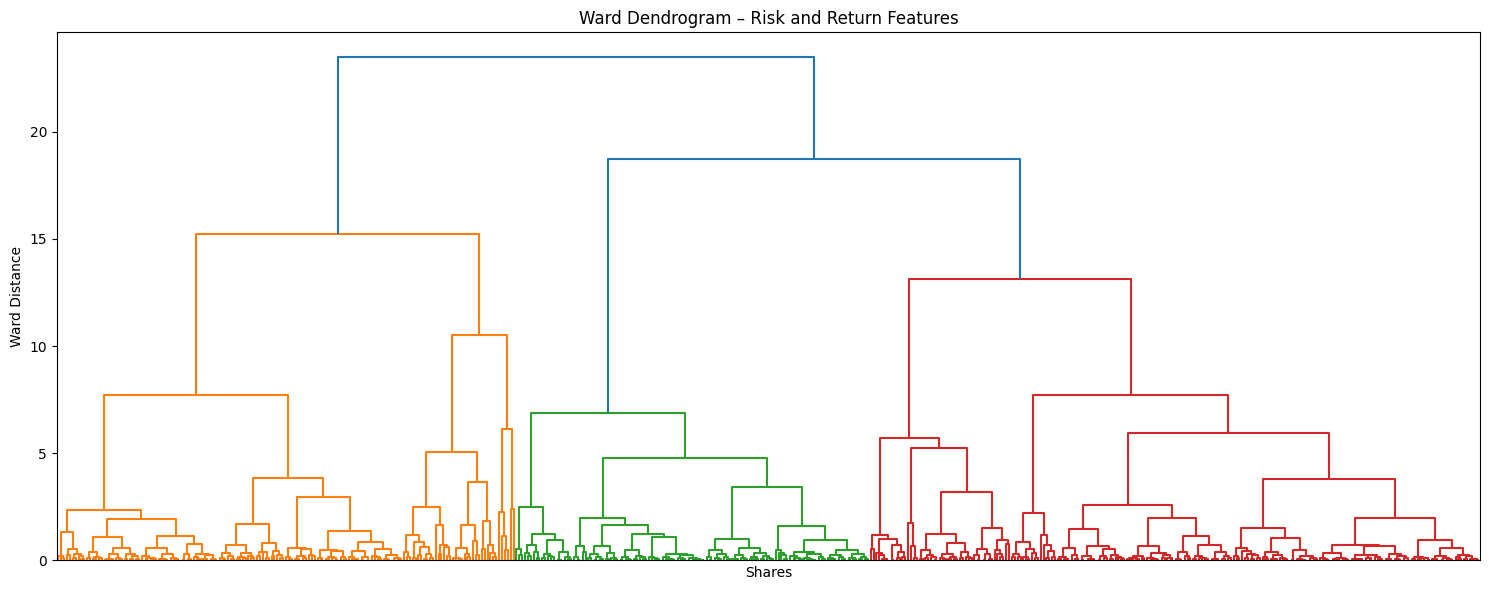

In [ ]:
# Hierarchical linkage for risk/return data
Z_risk = linkage(
    risk_standardised,
    method="ward",
    metric="euclidean"
)

# Plot dendrogram
plt.figure(figsize=(15, 6))

dendrogram(
    Z_risk,
    no_labels=True
)

plt.title("Ward Dendrogram – Risk and Return Features")
plt.xlabel("Shares")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.savefig(
    f"{OUTDIR}/ward_risk_dendrogram.png",
    dpi=160
)
plt.show()

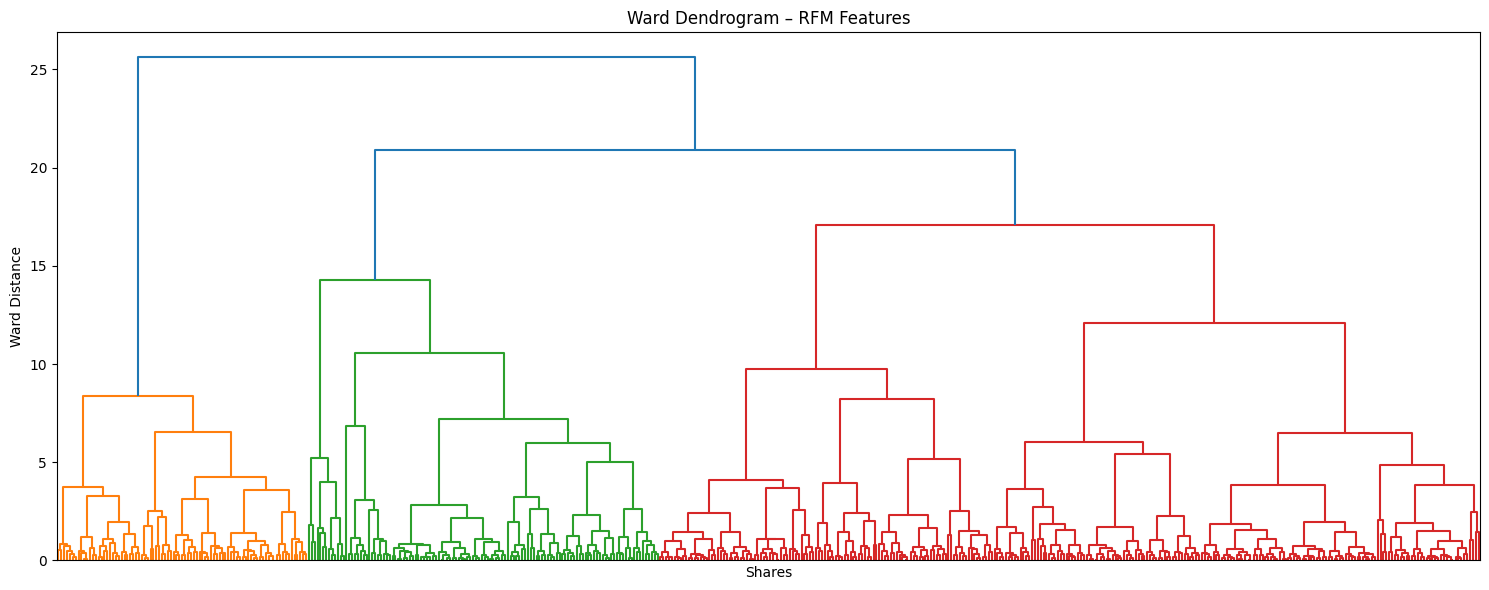

In [ ]:
# Hierarchical linkage for RFM data
Z_rfm = linkage(
    rfm_standardised,
    method="ward",
    metric="euclidean"
)

# Plot dendrogram
plt.figure(figsize=(15, 6))

dendrogram(
    Z_rfm,
    no_labels=True
)

plt.title("Ward Dendrogram – RFM Features")
plt.xlabel("Shares")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.savefig(
    f"{OUTDIR}/ward_rfm_dendrogram.png",
    dpi=160
)
plt.show()

In [ ]:
def ward_evaluation(X, name):

    results = []
    models = {}

    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        labels = model.fit_predict(X)

        score = silhouette_score(X, labels)

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            "k": k,
            "Silhouette": score,
            "Smallest_Cluster": cluster_sizes.min(),
            "Largest_Cluster": cluster_sizes.max(),
            "Cluster_Sizes": cluster_sizes.to_dict()
        })

        models[k] = labels

    results_df = pd.DataFrame(results)

    print(f"\n{name} – Ward clustering evaluation")
    display(results_df)

    results_df.to_csv(
        f"{OUTDIR}/{name.lower()}_ward_k_diagnostics.csv",
        index=False
    )

    return results_df, models

In [ ]:
ward_risk_results, ward_risk_models = ward_evaluation(
    risk_standardised,
    "RiskReturn"
)


RiskReturn – Ward clustering evaluation


,k,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,2,0.298828,159,335,"{0: 335, 1: 159}"
1,3,0.282999,123,212,"{0: 159, 1: 212, 2: 123}"
2,4,0.272840,39,212,"{0: 212, 1: 39, 2: 123, 3: 120}"
3,5,0.307755,39,163,"{0: 39, 1: 120, 2: 123, 3: 163, 4: 49}"
4,6,0.316912,6,163,"{0: 120, 1: 163, 2: 123, 3: 6, 4: 49, 5: 33}"
5,7,0.289788,6,163,"{0: 163, 1: 6, 2: 123, 3: 64, 4: 49, 5: 33, 6:..."
6,8,0.298220,6,147,"{0: 123, 1: 6, 2: 147, 3: 64, 4: 49, 5: 33, 6:..."


In [ ]:
ward_rfm_results, ward_rfm_models = ward_evaluation(
    rfm_standardised,
    "RFM"
)


RFM – Ward clustering evaluation


,k,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,2,0.286788,87,407,"{0: 407, 1: 87}"
1,3,0.237422,87,285,"{0: 285, 1: 87, 2: 122}"
2,4,0.202014,87,169,"{0: 122, 1: 116, 2: 169, 3: 87}"
3,5,0.216332,13,169,"{0: 169, 1: 116, 2: 109, 3: 87, 4: 13}"
4,6,0.195088,13,116,"{0: 109, 1: 116, 2: 97, 3: 87, 4: 13, 5: 72}"
5,7,0.204580,13,116,"{0: 116, 1: 87, 2: 16, 3: 93, 4: 13, 5: 72, 6:..."
6,8,0.198924,13,97,"{0: 87, 1: 62, 2: 16, 3: 93, 4: 13, 5: 72, 6: ..."


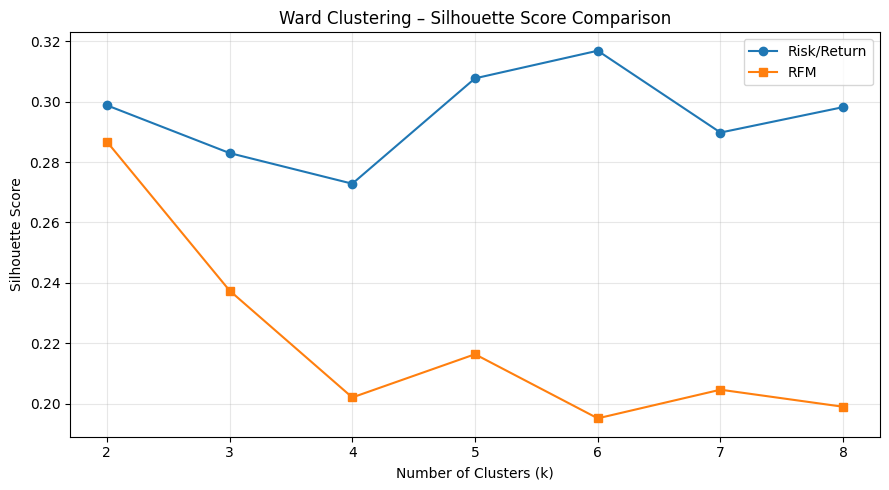

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    ward_risk_results["k"],
    ward_risk_results["Silhouette"],
    marker="o",
    label="Risk/Return"
)

plt.plot(
    ward_rfm_results["k"],
    ward_rfm_results["Silhouette"],
    marker="s",
    label="RFM"
)

plt.title("Ward Clustering – Silhouette Score Comparison")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTDIR}/ward_silhouette_comparison.png",
    dpi=160
)

plt.show()

In [ ]:
MIN_CLUSTER_SHARE = 0.05


def choose_k(results, n_shares, min_share=MIN_CLUSTER_SHARE):
    allowed = results[results["Smallest_Cluster"] >= min_share * n_shares]
    if allowed.empty:
        print("No k meets the minimum cluster size; using the highest silhouette.")
        allowed = results
    return int(allowed.loc[allowed["Silhouette"].idxmax(), "k"])


n_shares = len(risk_standardised)

K_WARD_RISK = choose_k(ward_risk_results, n_shares)
K_WARD_RFM = choose_k(ward_rfm_results, n_shares)

print("Minimum cluster size:", int(MIN_CLUSTER_SHARE * n_shares), "shares")
print("Selected Ward risk/return k:", K_WARD_RISK)
print("Selected Ward RFM k:", K_WARD_RFM)

Minimum cluster size: 24 shares
Selected Ward risk/return k: 5
Selected Ward RFM k: 2


In [ ]:
print("risk_matrix available:", "risk_matrix" in globals())
print("rfm_matrix_original available:", "rfm_matrix_original" in globals())

risk_matrix available: True
rfm_matrix_original available: True


In [ ]:
# Create final Ward cluster labels
ward_risk_labels = pd.Series(
    ward_risk_models[K_WARD_RISK],
    index=risk_standardised.index,
    name="Ward_Risk_Cluster"
)

ward_rfm_labels = pd.Series(
    ward_rfm_models[K_WARD_RFM],
    index=rfm_standardised.index,
    name="Ward_RFM_Cluster"
)

# Risk/return cluster profiles in original units
risk_profile_data = risk_matrix.join(ward_risk_labels)

risk_profiles = risk_profile_data.groupby(
    "Ward_Risk_Cluster"
).agg(
    Number_of_Shares=("MeanWeeklyReturn", "size"),
    Mean_Weekly_Return=("MeanWeeklyReturn", "mean"),
    Median_Weekly_Return=("MeanWeeklyReturn", "median"),
    Mean_Weekly_Beta=("WeeklyBeta", "mean"),
    Median_Weekly_Beta=("WeeklyBeta", "median")
)

print("Risk/return cluster profiles:")
display(risk_profiles.round(4))


# RFM cluster profiles in original units
rfm_profile_data = rfm_matrix_original.join(ward_rfm_labels)

rfm_profiles = rfm_profile_data.groupby(
    "Ward_RFM_Cluster"
).agg(
    Number_of_Shares=("RecencyDays", "size"),
    Mean_Recency=("RecencyDays", "mean"),
    Median_Recency=("RecencyDays", "median"),
    Mean_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Mean_Monetary_USD=("MonetaryUSD", "mean"),
    Median_Monetary_USD=("MonetaryUSD", "median")
)

print("RFM cluster profiles:")
display(rfm_profiles.round(2))

Risk/return cluster profiles:


,Number_of_Shares,Mean_Weekly_Return,Median_Weekly_Return,Mean_Weekly_Beta,Median_Weekly_Beta
Ward_Risk_Cluster,,,,,
0,39,0.0090,0.0079,1.4908,1.4196
1,120,0.0047,0.0046,0.9866,0.9886
2,123,0.0018,0.0020,0.5240,0.5187
3,163,0.0013,0.0015,1.0087,1.0014
4,49,0.0021,0.0025,1.6321,1.5184


RFM cluster profiles:


,Number_of_Shares,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary_USD,Median_Monetary_USD
Ward_RFM_Cluster,,,,,,,
0,407,68.75,36.0,110.72,111.0,5.597886e+08,2.201285e+08
1,87,507.95,334.0,103.85,104.0,4.789144e+08,3.363553e+08


In [ ]:
risk_profiles.to_csv(
    f"{OUTDIR}/ward_risk_cluster_profiles.csv"
)

rfm_profiles.to_csv(
    f"{OUTDIR}/ward_rfm_cluster_profiles.csv"
)

ward_risk_labels.to_csv(
    f"{OUTDIR}/ward_risk_cluster_assignments.csv"
)

ward_rfm_labels.to_csv(
    f"{OUTDIR}/ward_rfm_cluster_assignments.csv"
)

print("Task 2.2 outputs saved successfully.")

Task 2.2 outputs saved successfully.


Task 2.3

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
N_INIT = 50

OUTDIR = "coursework_outputs/Task_2_3"
os.makedirs(OUTDIR, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Check that Task 2.1 outputs exist
assert "risk_standardised" in globals(), \
    "Complete Task 2.1 risk standardisation first."

assert "rfm_standardised" in globals(), \
    "Complete Task 2.1 RFM standardisation first."

# Check the matrices
print("Risk matrix shape:", risk_standardised.shape)
print("RFM matrix shape:", rfm_standardised.shape)

print(
    "Same shares:",
    risk_standardised.index.equals(rfm_standardised.index)
)

# Check missing and infinite values
assert risk_standardised.notna().all().all()
assert rfm_standardised.notna().all().all()

assert np.isfinite(risk_standardised.to_numpy()).all()
assert np.isfinite(rfm_standardised.to_numpy()).all()

print("Input validation successful.")

Risk matrix shape: (494, 2)
RFM matrix shape: (494, 3)
Same shares: True
Input validation successful.


In [ ]:
def evaluate_kmeans(X, dataset_name):

    results = []
    models = {}
    labels_dict = {}

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=N_INIT,
            max_iter=300,
            random_state=RANDOM_STATE,
            algorithm="lloyd"
        )

        labels = model.fit_predict(X)

        silhouette = silhouette_score(
            X,
            labels
        )

        cluster_sizes = (
            pd.Series(labels)
            .value_counts()
            .sort_index()
        )

        results.append({
            "k": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette,
            "Smallest_Cluster": cluster_sizes.min(),
            "Largest_Cluster": cluster_sizes.max(),
            "Cluster_Sizes": cluster_sizes.to_dict()
        })

        models[k] = model
        labels_dict[k] = labels

    results_df = pd.DataFrame(results)

    print(f"\n{dataset_name} – K-Means Evaluation")
    display(results_df)

    results_df.to_csv(
        f"{OUTDIR}/{dataset_name.lower()}_kmeans_diagnostics.csv",
        index=False
    )

    return results_df, models, labels_dict

In [ ]:
risk_kmeans_results, risk_kmeans_models, risk_kmeans_labels = (
    evaluate_kmeans(
        risk_standardised,
        "Risk_Return"
    )
)


Risk_Return – K-Means Evaluation


,k,Inertia,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,2,629.068918,0.390872,146,348,"{0: 348, 1: 146}"
1,3,476.391224,0.318652,121,206,"{0: 206, 1: 167, 2: 121}"
2,4,376.169035,0.323266,39,173,"{0: 121, 1: 161, 2: 173, 3: 39}"
3,5,314.797377,0.336871,23,155,"{0: 155, 1: 23, 2: 129, 3: 132, 4: 55}"
4,6,262.248637,0.337545,7,162,"{0: 105, 1: 162, 2: 7, 3: 53, 4: 40, 5: 127}"
5,7,226.631168,0.333489,7,144,"{0: 87, 1: 42, 2: 49, 3: 92, 4: 7, 5: 73, 6: 144}"
6,8,194.331080,0.353305,7,139,"{0: 40, 1: 78, 2: 139, 3: 81, 4: 44, 5: 7, 6: ..."


In [ ]:
rfm_kmeans_results, rfm_kmeans_models, rfm_kmeans_labels = (
    evaluate_kmeans(
        rfm_standardised,
        "RFM"
    )
)


RFM – K-Means Evaluation


,k,Inertia,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,2,1051.872018,0.312090,165,329,"{0: 329, 1: 165}"
1,3,814.272383,0.307203,101,254,"{0: 101, 1: 139, 2: 254}"
2,4,695.866858,0.282670,80,207,"{0: 108, 1: 80, 2: 207, 3: 99}"
3,5,612.743761,0.256652,52,175,"{0: 66, 1: 175, 2: 107, 3: 94, 4: 52}"
4,6,550.040033,0.244840,48,139,"{0: 139, 1: 70, 2: 73, 3: 48, 4: 82, 5: 82}"
5,7,494.845938,0.253173,33,128,"{0: 86, 1: 80, 2: 68, 3: 33, 4: 128, 5: 64, 6:..."
6,8,451.753202,0.264566,28,96,"{0: 34, 1: 66, 2: 80, 3: 96, 4: 28, 5: 33, 6: ..."


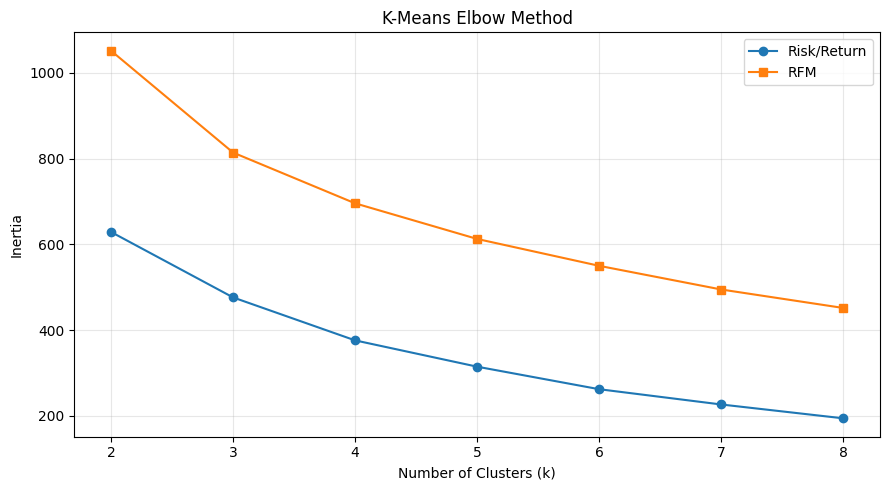

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    risk_kmeans_results["k"],
    risk_kmeans_results["Inertia"],
    marker="o",
    label="Risk/Return"
)

plt.plot(
    rfm_kmeans_results["k"],
    rfm_kmeans_results["Inertia"],
    marker="s",
    label="RFM"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTDIR}/kmeans_elbow_comparison.png",
    dpi=160
)

plt.show()

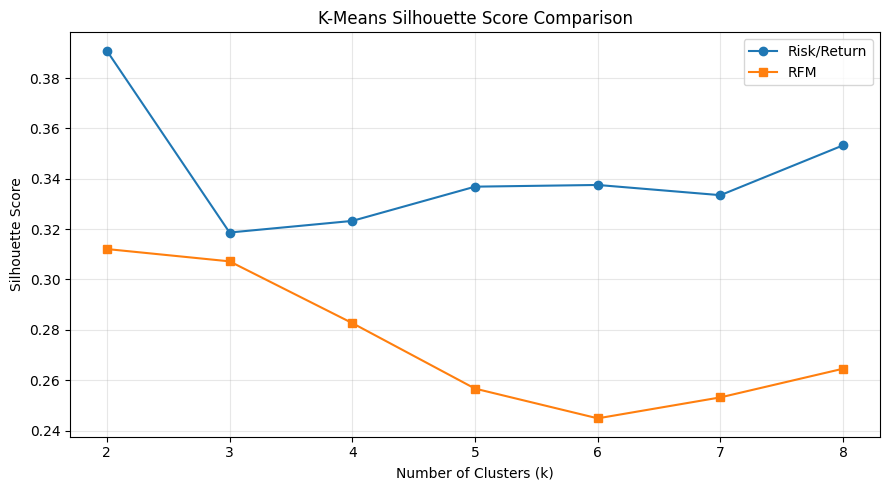

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    risk_kmeans_results["k"],
    risk_kmeans_results["Silhouette"],
    marker="o",
    label="Risk/Return"
)

plt.plot(
    rfm_kmeans_results["k"],
    rfm_kmeans_results["Silhouette"],
    marker="s",
    label="RFM"
)

plt.title("K-Means Silhouette Score Comparison")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTDIR}/kmeans_silhouette_comparison.png",
    dpi=160
)

plt.show()

In [ ]:
print("Risk/Return cluster sizes")

for k, labels in risk_kmeans_labels.items():

    sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    print(f"\nk = {k}")
    print(sizes)


print("\nRFM cluster sizes")

for k, labels in rfm_kmeans_labels.items():

    sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    print(f"\nk = {k}")
    print(sizes)

Risk/Return cluster sizes

k = 2
0    348
1    146
Name: count, dtype: int64

k = 3
0    206
1    167
2    121
Name: count, dtype: int64

k = 4
0    121
1    161
2    173
3     39
Name: count, dtype: int64

k = 5
0    155
1     23
2    129
3    132
4     55
Name: count, dtype: int64

k = 6
0    105
1    162
2      7
3     53
4     40
5    127
Name: count, dtype: int64

k = 7
0     87
1     42
2     49
3     92
4      7
5     73
6    144
Name: count, dtype: int64

k = 8
0     40
1     78
2    139
3     81
4     44
5      7
6     30
7     75
Name: count, dtype: int64

RFM cluster sizes

k = 2
0    329
1    165
Name: count, dtype: int64

k = 3
0    101
1    139
2    254
Name: count, dtype: int64

k = 4
0    108
1     80
2    207
3     99
Name: count, dtype: int64

k = 5
0     66
1    175
2    107
3     94
4     52
Name: count, dtype: int64

k = 6
0    139
1     70
2     73
3     48
4     82
5     82
Name: count, dtype: int64

k = 7
0     86
1     80
2     68
3     33
4    128
5     64
6  

In [ ]:
MIN_CLUSTER_SHARE = 0.05


def choose_k(results, n_shares, min_share=MIN_CLUSTER_SHARE):
    allowed = results[results["Smallest_Cluster"] >= min_share * n_shares]
    if allowed.empty:
        print("No k meets the minimum cluster size; using the highest silhouette.")
        allowed = results
    return int(allowed.loc[allowed["Silhouette"].idxmax(), "k"])


n_shares = len(risk_standardised)

K_KMEANS_RISK = choose_k(risk_kmeans_results, n_shares)
K_KMEANS_RFM = choose_k(rfm_kmeans_results, n_shares)

print("Minimum cluster size:", int(MIN_CLUSTER_SHARE * n_shares), "shares")
print("Selected K-Means risk/return k:", K_KMEANS_RISK)
print("Selected K-Means RFM k:", K_KMEANS_RFM)

Minimum cluster size: 24 shares
Selected K-Means risk/return k: 2
Selected K-Means RFM k: 2


In [ ]:
risk_kmeans_final_labels = pd.Series(
    risk_kmeans_labels[K_KMEANS_RISK],
    index=risk_standardised .index,
    name="KMeans_Risk_Cluster"
)

rfm_kmeans_final_labels = pd.Series(
    rfm_kmeans_labels[K_KMEANS_RFM],
    index=rfm_standardised.index,
    name="KMeans_RFM_Cluster"
)

risk_kmeans_final_labels.to_csv(
    f"{OUTDIR}/kmeans_risk_cluster_assignments.csv"
)

rfm_kmeans_final_labels.to_csv(
    f"{OUTDIR}/kmeans_rfm_cluster_assignments.csv"
)

print("K-Means cluster assignments saved.")

K-Means cluster assignments saved.


Task 2.4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

OUTDIR = "coursework_outputs/Task_2_4"
os.makedirs(OUTDIR, exist_ok=True)

required_variables = [
    "risk_matrix",
    "rfm_matrix_original",
    "risk_standardised",
    "rfm_standardised",
    "ward_risk_labels",
    "ward_rfm_labels",
    "risk_kmeans_final_labels",
    "rfm_kmeans_final_labels"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Complete the relevant earlier task first."
        )

print("All required datasets and cluster labels are available.")
print("Risk matrix:", risk_matrix.shape)
print("RFM matrix:", rfm_matrix_original.shape)

All required datasets and cluster labels are available.
Risk matrix: (494, 2)
RFM matrix: (494, 3)


In [ ]:
common_shares = (
    risk_matrix.index
    .intersection(rfm_matrix_original.index)
    .intersection(risk_standardised.index)
    .intersection(rfm_standardised.index)
    .intersection(ward_risk_labels.index)
    .intersection(ward_rfm_labels.index)
    .intersection(risk_kmeans_final_labels.index)
    .intersection(rfm_kmeans_final_labels.index)
)

# Sort consistently
common_shares = common_shares.sort_values()

# Align original feature matrices
risk_original_24 = risk_matrix.loc[common_shares].copy()
rfm_original_24 = rfm_matrix_original.loc[common_shares].copy()

# Align standardised matrices
risk_scaled_24 = risk_standardised.loc[common_shares].copy()
rfm_scaled_24 = rfm_standardised.loc[common_shares].copy()

# Align cluster labels
ward_risk_24 = ward_risk_labels.loc[common_shares]
ward_rfm_24 = ward_rfm_labels.loc[common_shares]

kmeans_risk_24 = risk_kmeans_final_labels.loc[common_shares]
kmeans_rfm_24 = rfm_kmeans_final_labels.loc[common_shares]

print("Number of common shares:", len(common_shares))
print("All datasets aligned successfully.")

Number of common shares: 494
All datasets aligned successfully.


In [ ]:
def create_risk_profile(features, labels, label_name):

    data = features.copy()
    data[label_name] = labels

    profile = data.groupby(label_name).agg(
        Number_of_Shares=("MeanWeeklyReturn", "size"),
        Mean_Weekly_Return=("MeanWeeklyReturn", "mean"),
        Median_Weekly_Return=("MeanWeeklyReturn", "median"),
        Mean_Weekly_Beta=("WeeklyBeta", "mean"),
        Median_Weekly_Beta=("WeeklyBeta", "median")
    )

    profile["Share_Percentage"] = (
        profile["Number_of_Shares"] /
        profile["Number_of_Shares"].sum() * 100
    )

    return profile


ward_risk_profile_24 = create_risk_profile(
    risk_original_24,
    ward_risk_24,
    "Ward_Cluster"
)

kmeans_risk_profile_24 = create_risk_profile(
    risk_original_24,
    kmeans_risk_24,
    "KMeans_Cluster"
)

print("Ward risk/return profiles:")
display(ward_risk_profile_24.round(4))

print("K-Means risk/return profiles:")
display(kmeans_risk_profile_24.round(4))

Ward risk/return profiles:


,Number_of_Shares,Mean_Weekly_Return,Median_Weekly_Return,Mean_Weekly_Beta,Median_Weekly_Beta,Share_Percentage
Ward_Cluster,,,,,,
0,39,0.0090,0.0079,1.4908,1.4196,7.8947
1,120,0.0047,0.0046,0.9866,0.9886,24.2915
2,123,0.0018,0.0020,0.5240,0.5187,24.8988
3,163,0.0013,0.0015,1.0087,1.0014,32.9960
4,49,0.0021,0.0025,1.6321,1.5184,9.9190


K-Means risk/return profiles:


,Number_of_Shares,Mean_Weekly_Return,Median_Weekly_Return,Mean_Weekly_Beta,Median_Weekly_Beta,Share_Percentage
KMeans_Cluster,,,,,,
0,348,0.0019,0.0019,0.8182,0.8412,70.4453
1,146,0.0055,0.0049,1.3745,1.2783,29.5547


In [ ]:
def create_rfm_profile(features, labels, label_name):

    data = features.copy()
    data[label_name] = labels

    profile = data.groupby(label_name).agg(
        Number_of_Shares=("RecencyDays", "size"),
        Mean_Recency_Days=("RecencyDays", "mean"),
        Median_Recency_Days=("RecencyDays", "median"),
        Mean_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Mean_Monetary_USD=("MonetaryUSD", "mean"),
        Median_Monetary_USD=("MonetaryUSD", "median")
    )

    profile["Share_Percentage"] = (
        profile["Number_of_Shares"] /
        profile["Number_of_Shares"].sum() * 100
    )

    return profile


ward_rfm_profile_24 = create_rfm_profile(
    rfm_original_24,
    ward_rfm_24,
    "Ward_Cluster"
)

kmeans_rfm_profile_24 = create_rfm_profile(
    rfm_original_24,
    kmeans_rfm_24,
    "KMeans_Cluster"
)

print("Ward RFM profiles:")
display(ward_rfm_profile_24.round(2))

print("K-Means RFM profiles:")
display(kmeans_rfm_profile_24.round(2))

Ward RFM profiles:


,Number_of_Shares,Mean_Recency_Days,Median_Recency_Days,Mean_Frequency,Median_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Share_Percentage
Ward_Cluster,,,,,,,,
0,407,68.75,36.0,110.72,111.0,5.597886e+08,2.201285e+08,82.39
1,87,507.95,334.0,103.85,104.0,4.789144e+08,3.363553e+08,17.61


K-Means RFM profiles:


,Number_of_Shares,Mean_Recency_Days,Median_Recency_Days,Mean_Frequency,Median_Frequency,Mean_Monetary_USD,Median_Monetary_USD,Share_Percentage
KMeans_Cluster,,,,,,,,
0,329,49.76,35.0,112.58,112.0,5.990015e+08,2.340848e+08,66.6
1,165,338.21,267.0,103.40,104.0,4.389577e+08,2.694009e+08,33.4


In [ ]:
risk_ari = adjusted_rand_score(
    ward_risk_24,
    kmeans_risk_24
)

rfm_ari = adjusted_rand_score(
    ward_rfm_24,
    kmeans_rfm_24
)

ari_results = pd.DataFrame({
    "Feature_Matrix": ["Risk/Return", "RFM"],
    "Adjusted_Rand_Index": [risk_ari, rfm_ari]
})

print("Ward vs K-Means membership comparison:")
display(ari_results.round(4))

Ward vs K-Means membership comparison:


,Feature_Matrix,Adjusted_Rand_Index
0,Risk/Return,0.2567
1,RFM,0.4417


In [ ]:
def plot_pca_clusters(X, ward_labels, kmeans_labels,
                      dataset_name, output_name):

    pca = PCA(n_components=2)

    components = pca.fit_transform(X)

    pca_df = pd.DataFrame(
        components,
        index=X.index,
        columns=["PC1", "PC2"]
    )

    variance = pca.explained_variance_ratio_

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    cluster_sets = [
        (ward_labels, "Ward Clustering"),
        (kmeans_labels, "K-Means Clustering")
    ]

    for ax, (labels, title) in zip(axes, cluster_sets):

        for cluster in sorted(pd.Series(labels).unique()):

            mask = np.asarray(labels) == cluster

            ax.scatter(
                pca_df.loc[mask, "PC1"],
                pca_df.loc[mask, "PC2"],
                label=f"Cluster {cluster}",
                alpha=0.65,
                s=25
            )

        ax.set_title(f"{dataset_name}: {title}")
        ax.set_xlabel(
            f"PC1 ({variance[0] * 100:.2f}% variance)"
        )
        ax.set_ylabel(
            f"PC2 ({variance[1] * 100:.2f}% variance)"
        )

        ax.legend(title="Cluster")
        ax.grid(alpha=0.25)

    plt.suptitle(
        f"{dataset_name} – PCA Cluster Visualisation"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTDIR}/{output_name}.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "Total variance explained by first two components:",
        round(variance.sum() * 100, 2),
        "%"
    )

    return pca_df, variance

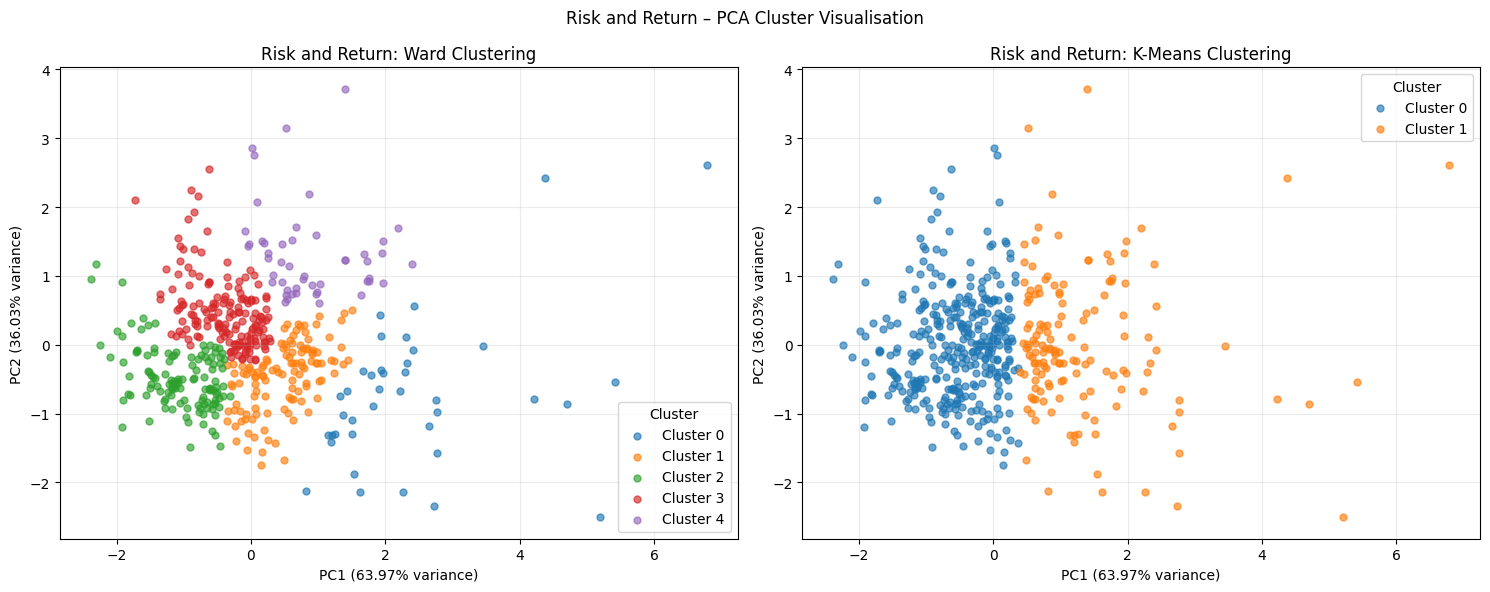

Total variance explained by first two components: 100.0 %


In [ ]:
risk_pca_df, risk_pca_variance = plot_pca_clusters(
    risk_scaled_24,   # FIX: was rfm_standardised (wrong feature matrix)
    ward_risk_24,
    kmeans_risk_24,
    "Risk and Return",
    "risk_pca_cluster_comparison"
)

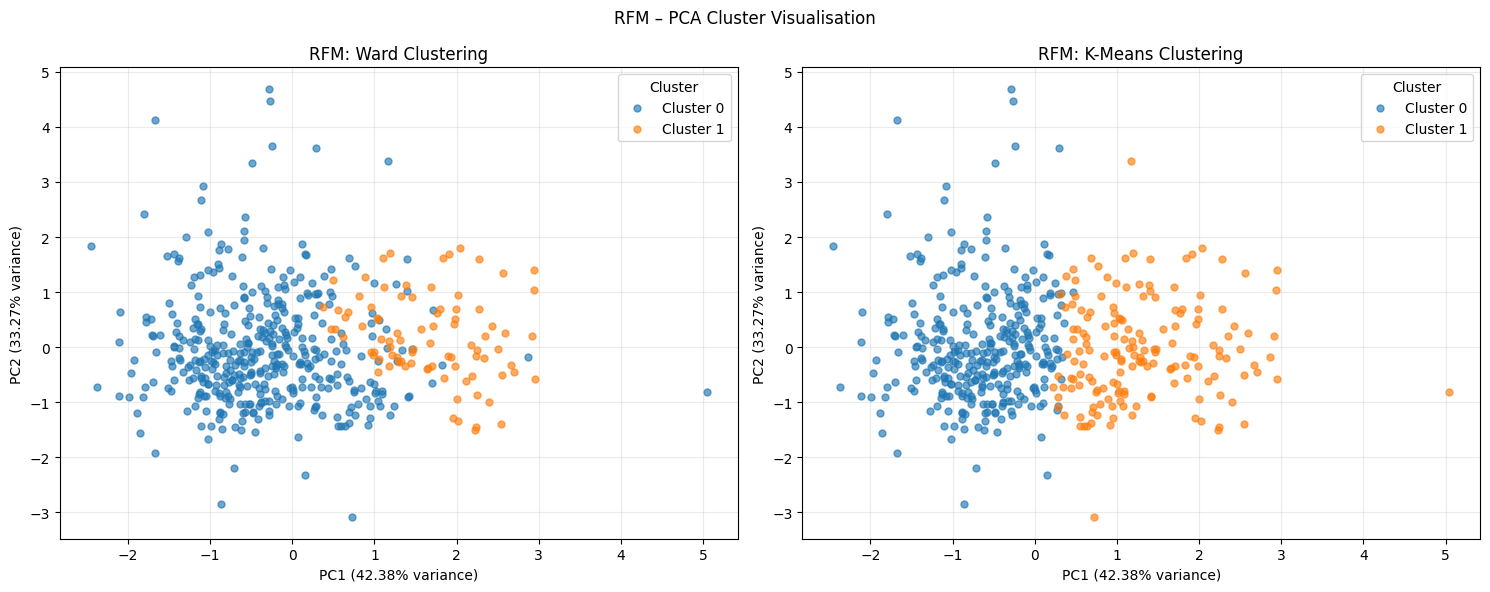

Total variance explained by first two components: 75.65 %


In [ ]:
rfm_pca_df, rfm_pca_variance = plot_pca_clusters(
    rfm_scaled_24,
    ward_rfm_24,
    kmeans_rfm_24,
    "RFM",
    "rfm_pca_cluster_comparison"
)

In [ ]:
def compare_cluster_sizes(ward_labels, kmeans_labels, dataset_name):

    ward_sizes = pd.Series(ward_labels).value_counts().sort_index()
    kmeans_sizes = pd.Series(kmeans_labels).value_counts().sort_index()

    result = pd.DataFrame({
        "Ward_Cluster_Size": ward_sizes,
        "KMeans_Cluster_Size": kmeans_sizes
    }).fillna(0).astype(int)

    print(f"{dataset_name} cluster sizes:")
    display(result)

    return result


risk_cluster_sizes_24 = compare_cluster_sizes(
    ward_risk_24,
    kmeans_risk_24,
    "Risk/Return"
)

rfm_cluster_sizes_24 = compare_cluster_sizes(
    ward_rfm_24,
    kmeans_rfm_24,
    "RFM"
)

# Cluster numbers are arbitrary in each algorithm (Ward cluster 0 is not
# K-Means cluster 0), so compare memberships with a crosstab
risk_crosstab_24 = pd.crosstab(ward_risk_24, kmeans_risk_24,
                               rownames=["Ward"], colnames=["KMeans"])
rfm_crosstab_24 = pd.crosstab(ward_rfm_24, kmeans_rfm_24,
                              rownames=["Ward"], colnames=["KMeans"])

print("Risk/Return: Ward vs K-Means membership")
display(risk_crosstab_24)
print("RFM: Ward vs K-Means membership")
display(rfm_crosstab_24)

Risk/Return cluster sizes:


,Ward_Cluster_Size,KMeans_Cluster_Size
0,39,348
1,120,146
2,123,0
3,163,0
4,49,0


RFM cluster sizes:


,Ward_Cluster_Size,KMeans_Cluster_Size
0,407,329
1,87,165


Risk/Return: Ward vs K-Means membership


KMeans,0,1
Ward,,
0,0,39
1,50,70
2,123,0
3,163,0
4,12,37


RFM: Ward vs K-Means membership


KMeans,0,1
Ward,,
0,329,78
1,0,87


In [ ]:
# Save original-unit cluster profiles
ward_risk_profile_24.to_csv(
    f"{OUTDIR}/ward_risk_profiles.csv"
)

kmeans_risk_profile_24.to_csv(
    f"{OUTDIR}/kmeans_risk_profiles.csv"
)

ward_rfm_profile_24.to_csv(
    f"{OUTDIR}/ward_rfm_profiles.csv"
)

kmeans_rfm_profile_24.to_csv(
    f"{OUTDIR}/kmeans_rfm_profiles.csv"
)

# Save algorithm comparison
ari_results.to_csv(
    f"{OUTDIR}/algorithm_ari_comparison.csv",
    index=False
)

risk_crosstab_24.to_csv(f"{OUTDIR}/risk_ward_vs_kmeans_crosstab.csv")
rfm_crosstab_24.to_csv(f"{OUTDIR}/rfm_ward_vs_kmeans_crosstab.csv")

risk_cluster_sizes_24.to_csv(
    f"{OUTDIR}/risk_cluster_size_comparison.csv"
)

rfm_cluster_sizes_24.to_csv(
    f"{OUTDIR}/rfm_cluster_size_comparison.csv"
)

# Save cluster assignments on the same shares
assignments_24 = pd.DataFrame({
    "Ward_Risk": ward_risk_24,
    "KMeans_Risk": kmeans_risk_24,
    "Ward_RFM": ward_rfm_24,
    "KMeans_RFM": kmeans_rfm_24
})

assignments_24.to_csv(
    f"{OUTDIR}/cluster_assignments_comparison.csv"
)

# Save PCA coordinates
risk_pca_df.to_csv(
    f"{OUTDIR}/risk_pca_coordinates.csv"
)

rfm_pca_df.to_csv(
    f"{OUTDIR}/rfm_pca_coordinates.csv"
)

print("All Task 2.4 outputs saved successfully.")

All Task 2.4 outputs saved successfully.


Task 2.5

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

TASK_25_DIR = "CRM_Coursework_Data/Task_2_5"
os.makedirs(TASK_25_DIR, exist_ok=True)

required_variables = [
    "common_shares", "sp500",
    "risk_original_24", "rfm_original_24",
    "ward_risk_24", "kmeans_risk_24",
    "ward_rfm_24", "kmeans_rfm_24"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(f"{variable} is missing. Complete Task 2.4 first.")

# One table with every share's cluster from each method
segments_25 = pd.DataFrame({
    "Ward_Risk": ward_risk_24,
    "KMeans_Risk": kmeans_risk_24,
    "Ward_RFM": ward_rfm_24,
    "KMeans_RFM": kmeans_rfm_24
}).loc[common_shares]

print("Shares in Task 2.5:", len(segments_25))
display(segments_25.head())

Shares in Task 2.5: 494


,Ward_Risk,KMeans_Risk,Ward_RFM,KMeans_RFM
Ticker,,,,
A,3,0,1,1
AAPL,1,1,0,0
ABBV,2,0,0,0
ABNB,4,1,1,1
ABT,2,0,0,1


In [ ]:
# Agreement between the risk/return and RFM segmentations
pairs = [
    ("Ward_Risk", "Ward_RFM"),
    ("KMeans_Risk", "KMeans_RFM"),
    ("Ward_Risk", "KMeans_RFM"),
    ("KMeans_Risk", "Ward_RFM"),
    ("Ward_Risk", "KMeans_Risk"),
    ("Ward_RFM", "KMeans_RFM")
]

agreement_25 = pd.DataFrame([
    {
        "Segmentation_A": a,
        "Segmentation_B": b,
        "Adjusted_Rand_Index": adjusted_rand_score(segments_25[a], segments_25[b]),
        "Normalised_Mutual_Info": normalized_mutual_info_score(segments_25[a], segments_25[b])
    }
    for a, b in pairs
])

print("Agreement between segmentations (1 = identical, 0 = no relationship):")
display(agreement_25.round(4))

agreement_25.to_csv(f"{TASK_25_DIR}/segmentation_agreement.csv", index=False)

Agreement between segmentations (1 = identical, 0 = no relationship):


,Segmentation_A,Segmentation_B,Adjusted_Rand_Index,Normalised_Mutual_Info
0,Ward_Risk,Ward_RFM,-0.0040,0.0205
1,KMeans_Risk,KMeans_RFM,-0.0187,0.0360
2,Ward_Risk,KMeans_RFM,0.0336,0.0596
3,KMeans_Risk,Ward_RFM,-0.0393,0.0128
4,Ward_Risk,KMeans_Risk,0.2567,0.3697
5,Ward_RFM,KMeans_RFM,0.4417,0.4253


In [ ]:
# Cross-tabulation: risk/return clusters vs RFM clusters
for risk_col, rfm_col in [("KMeans_Risk", "KMeans_RFM"), ("Ward_Risk", "Ward_RFM")]:

    table = pd.crosstab(
        segments_25[risk_col],
        segments_25[rfm_col],
        margins=True,
        margins_name="Total"
    )

    row_pct = pd.crosstab(
        segments_25[risk_col],
        segments_25[rfm_col],
        normalize="index"
    ) * 100

    print(f"{risk_col} vs {rfm_col} (counts):")
    display(table)

    print(f"{risk_col} vs {rfm_col} (% of each risk cluster):")
    display(row_pct.round(1))

    table.to_csv(f"{TASK_25_DIR}/{risk_col}_vs_{rfm_col}_counts.csv")
    row_pct.to_csv(f"{TASK_25_DIR}/{risk_col}_vs_{rfm_col}_row_pct.csv")

KMeans_Risk vs KMeans_RFM (counts):


KMeans_RFM,0,1,Total
KMeans_Risk,,,
0,210,138,348
1,119,27,146
Total,329,165,494


KMeans_Risk vs KMeans_RFM (% of each risk cluster):


KMeans_RFM,0,1
KMeans_Risk,,
0,60.3,39.7
1,81.5,18.5


Ward_Risk vs Ward_RFM (counts):


Ward_RFM,0,1,Total
Ward_Risk,,,
0,37,2,39
1,109,11,120
2,102,21,123
3,123,40,163
4,36,13,49
Total,407,87,494


Ward_Risk vs Ward_RFM (% of each risk cluster):


Ward_RFM,0,1
Ward_Risk,,
0,94.9,5.1
1,90.8,9.2
2,82.9,17.1
3,75.5,24.5
4,73.5,26.5


In [ ]:
# Sector composition of each cluster (GICS sector from the Wikipedia S&P 500 table)
sector_map = sp500.assign(
    Ticker=sp500["Symbol"].str.replace(".", "-", regex=False)
).set_index("Ticker")["GICS Sector"]

segments_25["Sector"] = sector_map.reindex(segments_25.index)

print("Shares without a sector:", segments_25["Sector"].isna().sum())

sector_tables_25 = {}

for col in ["KMeans_Risk", "Ward_Risk", "KMeans_RFM", "Ward_RFM"]:

    sector_pct = pd.crosstab(
        segments_25["Sector"],
        segments_25[col],
        normalize="columns"
    ) * 100

    sector_tables_25[col] = sector_pct

    print(f"Sector mix (%) by {col} cluster:")
    display(sector_pct.round(1))

    sector_pct.to_csv(f"{TASK_25_DIR}/sector_mix_{col}.csv")

Shares without a sector: 0
Sector mix (%) by KMeans_Risk cluster:


KMeans_Risk,0,1
Sector,,
Communication Services,4.3,4.1
Consumer Discretionary,6.9,15.8
Consumer Staples,8.9,0.7
Energy,3.4,6.2
Financials,16.4,13.0
Health Care,16.4,1.4
Industrials,14.7,19.2
Information Technology,7.5,32.9
Materials,5.7,2.7


Sector mix (%) by Ward_Risk cluster:


Ward_Risk,0,1,2,3,4
Sector,,,,,
Communication Services,2.6,5.0,5.7,4.3,0.0
Consumer Discretionary,10.3,13.3,2.4,8.6,20.4
Consumer Staples,0.0,1.7,20.3,3.1,0.0
Energy,10.3,13.3,0.8,0.0,0.0
Financials,12.8,20.8,11.4,16.0,12.2
Health Care,2.6,5.8,19.5,14.1,8.2
Industrials,17.9,18.3,8.9,21.5,8.2
Information Technology,33.3,15.0,1.6,11.0,46.9
Materials,2.6,2.5,3.3,8.6,4.1


Sector mix (%) by KMeans_RFM cluster:


KMeans_RFM,0,1
Sector,,
Communication Services,4.6,3.6
Consumer Discretionary,10.3,7.9
Consumer Staples,4.0,11.5
Energy,4.3,4.2
Financials,20.4,5.5
Health Care,7.6,20.6
Industrials,17.0,13.9
Information Technology,14.9,15.2
Materials,3.6,7.3


Sector mix (%) by Ward_RFM cluster:


Ward_RFM,0,1
Sector,,
Communication Services,4.2,4.6
Consumer Discretionary,9.3,10.3
Consumer Staples,4.4,16.1
Energy,3.7,6.9
Financials,18.2,2.3
Health Care,9.6,23.0
Industrials,18.2,5.7
Information Technology,14.3,18.4
Materials,4.4,6.9


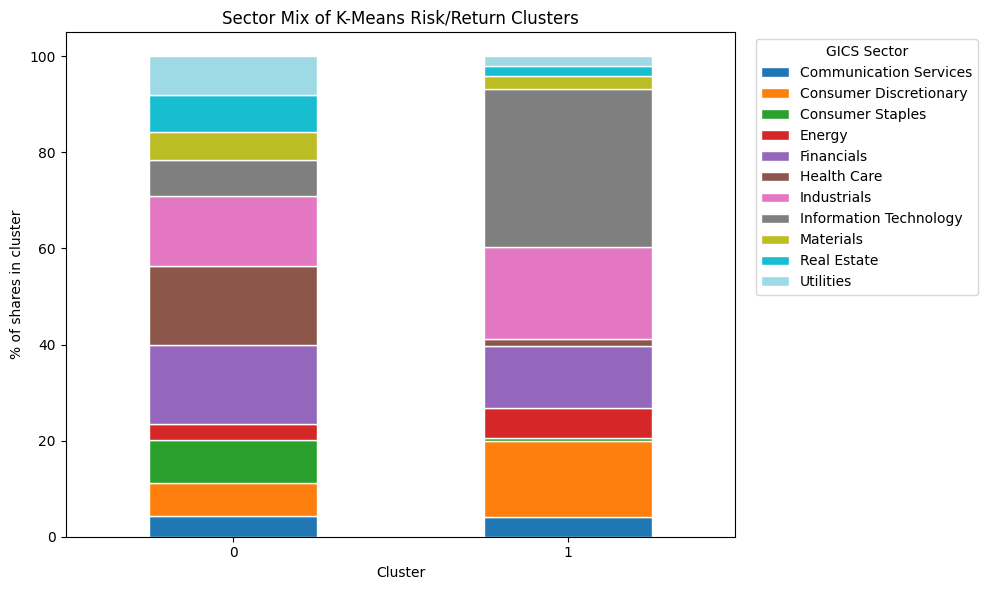

In [ ]:
# Stacked bar chart of sector mix for the K-Means risk/return clusters
sector_pct = sector_tables_25["KMeans_Risk"]

ax = sector_pct.T.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_title("Sector Mix of K-Means Risk/Return Clusters")
ax.set_xlabel("Cluster")
ax.set_ylabel("% of shares in cluster")
ax.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{TASK_25_DIR}/kmeans_risk_sector_mix.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
# Combined profile: risk/return and RFM features for each K-Means risk/return cluster
combined_25 = risk_original_24.join(rfm_original_24).join(segments_25)

final_profile_25 = combined_25.groupby("KMeans_Risk").agg(
    Number_of_Shares=("MeanWeeklyReturn", "size"),
    Mean_Weekly_Return=("MeanWeeklyReturn", "mean"),
    Mean_Weekly_Beta=("WeeklyBeta", "mean"),
    Mean_Frequency=("Frequency", "mean"),
    Median_Monetary_USD=("MonetaryUSD", "median"),
    Top_Sector=("Sector", lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
)

final_profile_25["Annualised_Return_%"] = (
    (1 + final_profile_25["Mean_Weekly_Return"]) ** 52 - 1
) * 100

# Label clusters relative to the market (beta = 1) and the median return
median_return = combined_25["MeanWeeklyReturn"].median()

final_profile_25["Segment_Label"] = np.where(
    final_profile_25["Mean_Weekly_Beta"] >= 1, "High beta", "Low beta"
) + " / " + np.where(
    final_profile_25["Mean_Weekly_Return"] >= median_return, "higher return", "lower return"
)

print("Final K-Means risk/return segment profile:")
display(final_profile_25.round(4))

final_profile_25.to_csv(f"{TASK_25_DIR}/final_segment_profile.csv")
segments_25.to_csv(f"{TASK_25_DIR}/all_segment_assignments.csv")

print("Task 2.5 outputs saved in:", TASK_25_DIR)

Final K-Means risk/return segment profile:


,Number_of_Shares,Mean_Weekly_Return,Mean_Weekly_Beta,Mean_Frequency,Median_Monetary_USD,Top_Sector,Annualised_Return_%,Segment_Label
KMeans_Risk,,,,,,,,
0,348,0.0019,0.8182,108.5287,2.234286e+08,Financials,10.1347,Low beta / lower return
1,146,0.0055,1.3745,111.8630,2.999318e+08,Information Technology,32.7030,High beta / higher return


Task 2.5 outputs saved in: CRM_Coursework_Data/Task_2_5


Task 03

In [ ]:
import os
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")

TASK_3_DIR = "CRM_Coursework_Data/Task_3"
os.makedirs(TASK_3_DIR, exist_ok=True)

required_variables = [
    "valid_daily", "weekly_prices", "benchmark_weekly_prices",
    "risk_standardised", "risk_matrix",
    "risk_kmeans_models", "K_KMEANS_RISK",
    "risk_kmeans_final_labels", "ward_risk_labels",
    "start_ts", "end_ts", "BENCHMARK_TICKER"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(f"{variable} is missing. Run Tasks 1 and 2 first.")

print("All Task 1 and Task 2 outputs are available.")
print("Output folder:", TASK_3_DIR)

All Task 1 and Task 2 outputs are available.
Output folder: CRM_Coursework_Data/Task_3


In [ ]:
RSI_PERIOD = 14
OVERBOUGHT = 70
OVERSOLD = 30


def compute_rsi(prices, period=RSI_PERIOD):
    """Wilder's RSI on a price series (exponential smoothing with alpha = 1/period)."""
    change = prices.diff()

    gains = change.clip(lower=0)
    losses = -change.clip(upper=0)

    avg_gain = gains.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    avg_loss = losses.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()

    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))

    # No losses in the window -> RSI = 100
    rsi = rsi.where(avg_loss != 0, 100)

    return rsi


rsi_series = {}
rsi_results = []

for ticker, df in valid_daily.items():

    if ticker == BENCHMARK_TICKER:
        continue

    prices = df["Adj Close"].copy()
    prices.index = pd.to_datetime(prices.index)
    if prices.index.tz is not None:
        prices.index = prices.index.tz_localize(None)

    prices = prices.sort_index()
    prices = prices.loc[(prices.index >= start_ts) & (prices.index < end_ts)]

    rsi = compute_rsi(prices).dropna()

    if rsi.empty:
        continue

    rsi_series[ticker] = rsi

    rsi_results.append({
        "Ticker": ticker,
        "Mean_RSI": rsi.mean(),
        "Final_RSI": rsi.iloc[-1],
        "Pct_Days_Overbought": (rsi > OVERBOUGHT).mean() * 100,
        "Pct_Days_Oversold": (rsi < OVERSOLD).mean() * 100,
        "RSI_Observations": len(rsi)
    })

rsi_features = pd.DataFrame(rsi_results).set_index("Ticker").sort_index()

print("RSI calculated for", len(rsi_features), "shares.")
display(rsi_features.head(10).round(2))

print("\nSummary statistics:")
display(rsi_features.describe().round(2))

rsi_features.to_csv(f"{TASK_3_DIR}/rsi_features.csv")

RSI calculated for 494 shares.


,Mean_RSI,Final_RSI,Pct_Days_Overbought,Pct_Days_Oversold,RSI_Observations
Ticker,,,,,
A,51.31,45.07,8.48,3.53,991
AAPL,53.96,56.72,10.19,1.31,991
ABBV,54.51,50.37,15.04,3.03,991
ABNB,50.52,43.95,4.84,2.83,991
ABT,51.24,42.38,7.06,3.33,991
ACGL,55.06,42.71,8.27,1.21,991
ACN,53.47,44.07,11.10,3.43,991
ADBE,51.45,32.12,9.89,4.24,991
ADI,51.89,44.87,2.32,0.71,991



Summary statistics:


,Mean_RSI,Final_RSI,Pct_Days_Overbought,Pct_Days_Oversold,RSI_Observations
count,494.00,494.00,494.00,494.00,494.00
mean,52.32,41.32,7.75,3.20,988.85
std,1.92,8.32,3.00,1.89,26.25
min,46.73,19.43,1.82,0.00,499.00
25%,51.12,36.13,5.58,1.72,991.00
50%,52.32,41.36,7.37,2.83,991.00
75%,53.57,46.07,9.69,4.31,991.00
max,58.06,69.94,17.86,10.39,991.00


In [ ]:
# Profile RSI by K-Means and Ward risk/return cluster
rsi_cluster_data = rsi_features.join(
    [risk_kmeans_final_labels, ward_risk_labels],
    how="inner"
)


def rsi_profile(data, label):
    return data.groupby(label).agg(
        Number_of_Shares=("Mean_RSI", "size"),
        Mean_RSI=("Mean_RSI", "mean"),
        Median_RSI=("Mean_RSI", "median"),
        Mean_Final_RSI=("Final_RSI", "mean"),
        Pct_Days_Overbought=("Pct_Days_Overbought", "mean"),
        Pct_Days_Oversold=("Pct_Days_Oversold", "mean")
    )


kmeans_rsi_profile = rsi_profile(rsi_cluster_data, "KMeans_Risk_Cluster")
ward_rsi_profile = rsi_profile(rsi_cluster_data, "Ward_Risk_Cluster")

print("RSI profile by K-Means risk/return cluster:")
display(kmeans_rsi_profile.round(2))

print("\nRSI profile by Ward risk/return cluster:")
display(ward_rsi_profile.round(2))

# Signal at the end of the study period
final_signal = pd.cut(
    rsi_cluster_data["Final_RSI"],
    bins=[-np.inf, OVERSOLD, OVERBOUGHT, np.inf],
    labels=["Oversold (<30)", "Neutral (30-70)", "Overbought (>70)"]
)

signal_table = pd.crosstab(
    rsi_cluster_data["KMeans_Risk_Cluster"],
    final_signal,
    dropna=False
)

print("\nRSI signal on the last trading day, by K-Means cluster:")
display(signal_table)

kmeans_rsi_profile.to_csv(f"{TASK_3_DIR}/kmeans_rsi_profile.csv")
ward_rsi_profile.to_csv(f"{TASK_3_DIR}/ward_rsi_profile.csv")
signal_table.to_csv(f"{TASK_3_DIR}/final_rsi_signal_by_cluster.csv")

RSI profile by K-Means risk/return cluster:


,Number_of_Shares,Mean_RSI,Median_RSI,Mean_Final_RSI,Pct_Days_Overbought,Pct_Days_Oversold
KMeans_Risk_Cluster,,,,,,
0,348,51.85,51.89,40.94,6.93,3.56
1,146,53.43,53.55,42.25,9.69,2.35



RSI profile by Ward risk/return cluster:


,Number_of_Shares,Mean_RSI,Median_RSI,Mean_Final_RSI,Pct_Days_Overbought,Pct_Days_Oversold
Ward_Risk_Cluster,,,,,,
0,39,54.60,54.92,43.88,11.68,1.81
1,120,53.92,53.96,41.38,9.73,2.02
2,123,51.94,52.19,41.41,6.78,3.65
3,163,51.25,51.50,40.36,6.35,3.97
4,49,51.07,51.10,42.15,6.83,3.56



RSI signal on the last trading day, by K-Means cluster:


Final_RSI,Oversold (<30),Neutral (30-70),Overbought (>70)
KMeans_Risk_Cluster,,,
0,27,321,0
1,15,131,0


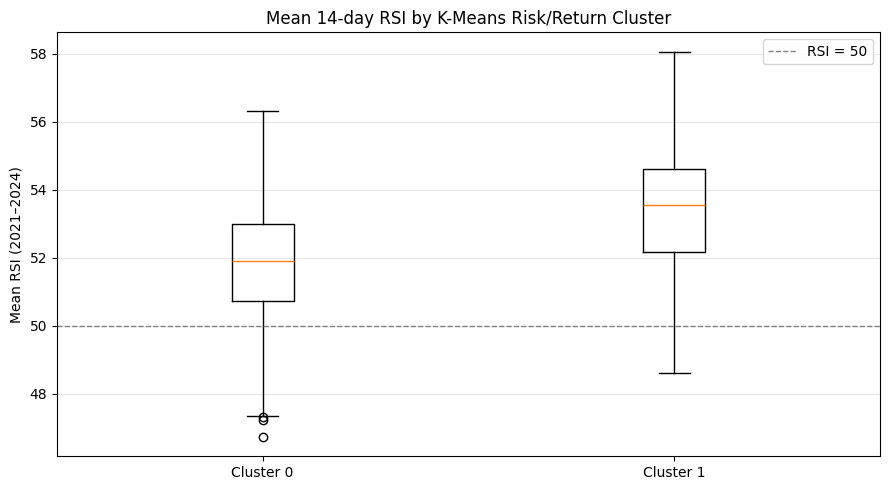

In [ ]:
# Mean RSI distribution by K-Means cluster
clusters = sorted(rsi_cluster_data["KMeans_Risk_Cluster"].unique())

plt.figure(figsize=(9, 5))
plt.boxplot(
    [rsi_cluster_data.loc[rsi_cluster_data["KMeans_Risk_Cluster"] == c, "Mean_RSI"]
     for c in clusters]
)
plt.xticks(range(1, len(clusters) + 1), [f"Cluster {c}" for c in clusters])
plt.axhline(50, color="grey", linestyle="--", linewidth=1, label="RSI = 50")
plt.title("Mean 14-day RSI by K-Means Risk/Return Cluster")
plt.ylabel("Mean RSI (2021–2024)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{TASK_3_DIR}/rsi_by_cluster_boxplot.png", dpi=160)
plt.show()

In [ ]:
# Representative share = the share closest to its K-Means centroid
kmeans_model = risk_kmeans_models[K_KMEANS_RISK]
centroids = kmeans_model.cluster_centers_

X_risk_rep = risk_standardised.loc[risk_kmeans_final_labels.index]

representatives = []

for cluster_id in sorted(risk_kmeans_final_labels.unique()):

    members = risk_kmeans_final_labels[
        risk_kmeans_final_labels == cluster_id
    ].index

    distances = np.linalg.norm(
        X_risk_rep.loc[members].to_numpy() - centroids[cluster_id],
        axis=1
    )

    closest = members[np.argmin(distances)]

    representatives.append({
        "Cluster": cluster_id,
        "Ticker": closest,
        "Distance_to_Centroid": distances.min(),
        "MeanWeeklyReturn": risk_matrix.loc[closest, "MeanWeeklyReturn"],
        "WeeklyBeta": risk_matrix.loc[closest, "WeeklyBeta"],
        "Mean_RSI": rsi_features.loc[closest, "Mean_RSI"]
        if closest in rsi_features.index else np.nan
    })

representatives = pd.DataFrame(representatives).set_index("Cluster")

print("Representative shares:")
display(representatives.round(4))

representatives.to_csv(f"{TASK_3_DIR}/representative_shares.csv")

# Series to forecast: one share per cluster + the S&P 500 benchmark
forecast_series = {
    f"{row.Ticker} (Cluster {cluster})": weekly_prices[row.Ticker].dropna()
    for cluster, row in representatives.iterrows()
}
forecast_series[f"{BENCHMARK_TICKER} (Benchmark)"] = benchmark_weekly_prices.dropna()

print("\nSeries to forecast:", list(forecast_series.keys()))

Representative shares:


,Ticker,Distance_to_Centroid,MeanWeeklyReturn,WeeklyBeta,Mean_RSI
Cluster,,,,,
0,CPT,0.0378,0.0019,0.8151,52.2356
1,NUE,0.0387,0.0056,1.3734,52.8576



Series to forecast: ['CPT (Cluster 0)', 'NUE (Cluster 1)', '^GSPC (Benchmark)']


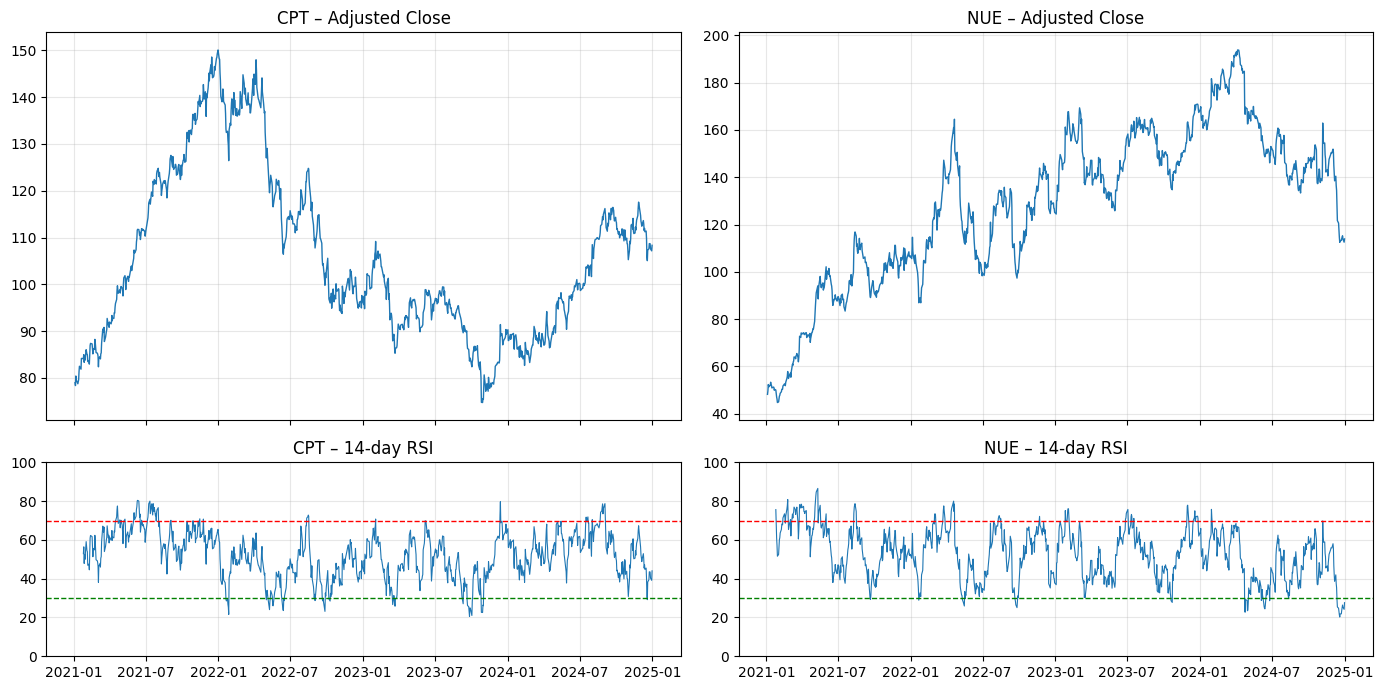

In [ ]:
# Price and RSI for each representative share
rep_tickers = representatives["Ticker"].tolist()

fig, axes = plt.subplots(
    2, len(rep_tickers),
    figsize=(7 * len(rep_tickers), 7),
    sharex="col",
    gridspec_kw={"height_ratios": [2, 1]},
    squeeze=False
)

for col, ticker in enumerate(rep_tickers):

    prices = valid_daily[ticker]["Adj Close"]
    prices = prices.loc[(prices.index >= start_ts) & (prices.index < end_ts)]

    axes[0, col].plot(prices.index, prices, linewidth=1)
    axes[0, col].set_title(f"{ticker} – Adjusted Close")
    axes[0, col].grid(alpha=0.3)

    axes[1, col].plot(rsi_series[ticker].index, rsi_series[ticker], linewidth=0.8)
    axes[1, col].axhline(OVERBOUGHT, color="red", linestyle="--", linewidth=1)
    axes[1, col].axhline(OVERSOLD, color="green", linestyle="--", linewidth=1)
    axes[1, col].set_ylim(0, 100)
    axes[1, col].set_title(f"{ticker} – 14-day RSI")
    axes[1, col].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{TASK_3_DIR}/representative_price_rsi.png", dpi=160)
plt.show()

In [ ]:
adf_results = []

for name, prices in forecast_series.items():

    log_prices = np.log(prices)
    log_returns = log_prices.diff().dropna()

    for series_name, series in [("Log price", log_prices), ("Log return", log_returns)]:

        stat, p_value, *_ = adfuller(series, autolag="AIC")

        adf_results.append({
            "Series": name,
            "Transformation": series_name,
            "ADF_Statistic": stat,
            "p_value": p_value,
            "Stationary_at_5%": p_value < 0.05
        })

adf_results = pd.DataFrame(adf_results)

print("ADF test results:")
display(adf_results.round(4))

adf_results.to_csv(f"{TASK_3_DIR}/adf_results.csv", index=False)


ADF test results:


,Series,Transformation,ADF_Statistic,p_value,Stationary_at_5%
0,CPT (Cluster 0),Log price,-1.8772,0.3429,False
1,CPT (Cluster 0),Log return,-14.4268,0.0000,True
2,NUE (Cluster 1),Log price,-3.0207,0.0330,True
3,NUE (Cluster 1),Log return,-13.3905,0.0000,True
4,^GSPC (Benchmark),Log price,-0.5478,0.8823,False
5,^GSPC (Benchmark),Log return,-15.4939,0.0000,True


In [ ]:
TRAIN_END = pd.Timestamp("2023-12-31")


def split_series(prices):
    train = prices.loc[prices.index <= TRAIN_END]
    test = prices.loc[prices.index > TRAIN_END]
    return train, test


def select_arima(log_train, max_p=2, max_q=2):
    best = None
    for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
        try:
            # Include a drift term (constant in differences)
            fit = ARIMA(log_train, order=(p, 1, q), trend="t").fit()
        except Exception:
            continue
        if best is None or fit.aic < best[1].aic:
            best = ((p, 1, q), fit)
    return best


def evaluate(actual, forecast):
    error = actual - forecast
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE_%": np.mean(np.abs(error / actual)) * 100
    }


forecast_results = []
forecast_outputs = {}
arima_fits = {}

for name, prices in forecast_series.items():

    train, test = split_series(prices)
    h = len(test)

    log_train = np.log(train).reset_index(drop=True)

    forecasts = {}

    # Naive
    forecasts["Naive"] = np.repeat(train.iloc[-1], h)

    # Drift
    drift = (log_train.iloc[-1] - log_train.iloc[0]) / (len(log_train) - 1)
    forecasts["Drift"] = np.exp(log_train.iloc[-1] + drift * np.arange(1, h + 1))

    # Holt (damped additive trend)
    holt = ExponentialSmoothing(
        log_train, trend="add", damped_trend=True
    ).fit(optimized=True)
    forecasts["Holt"] = np.exp(holt.forecast(h).to_numpy())

    # ARIMA chosen by AIC
    order, arima_fit = select_arima(log_train)
    arima_fits[name] = (order, arima_fit)
    forecasts[f"ARIMA{order}"] = np.exp(arima_fit.forecast(h).to_numpy())

    output = pd.DataFrame({"Actual": test.to_numpy()}, index=test.index)

    for model_name, values in forecasts.items():
        output[model_name] = values
        forecast_results.append({
            "Series": name,
            "Model": model_name,
            **evaluate(test.to_numpy(), np.asarray(values))
        })

    forecast_outputs[name] = output

    print(f"{name}: train = {len(train)} weeks, test = {h} weeks, "
          f"selected ARIMA{order} (AIC = {arima_fit.aic:.2f})")

forecast_results = pd.DataFrame(forecast_results)

# Save forecasts
pd.concat(forecast_outputs, names=["Series", "Week"]).to_csv(
    f"{TASK_3_DIR}/forecasts_2024.csv"
)

CPT (Cluster 0): train = 156 weeks, test = 52 weeks, selected ARIMA(0, 1, 0) (AIC = -617.17)
NUE (Cluster 1): train = 156 weeks, test = 52 weeks, selected ARIMA(0, 1, 0) (AIC = -417.50)
^GSPC (Benchmark): train = 156 weeks, test = 52 weeks, selected ARIMA(0, 1, 0) (AIC = -718.57)


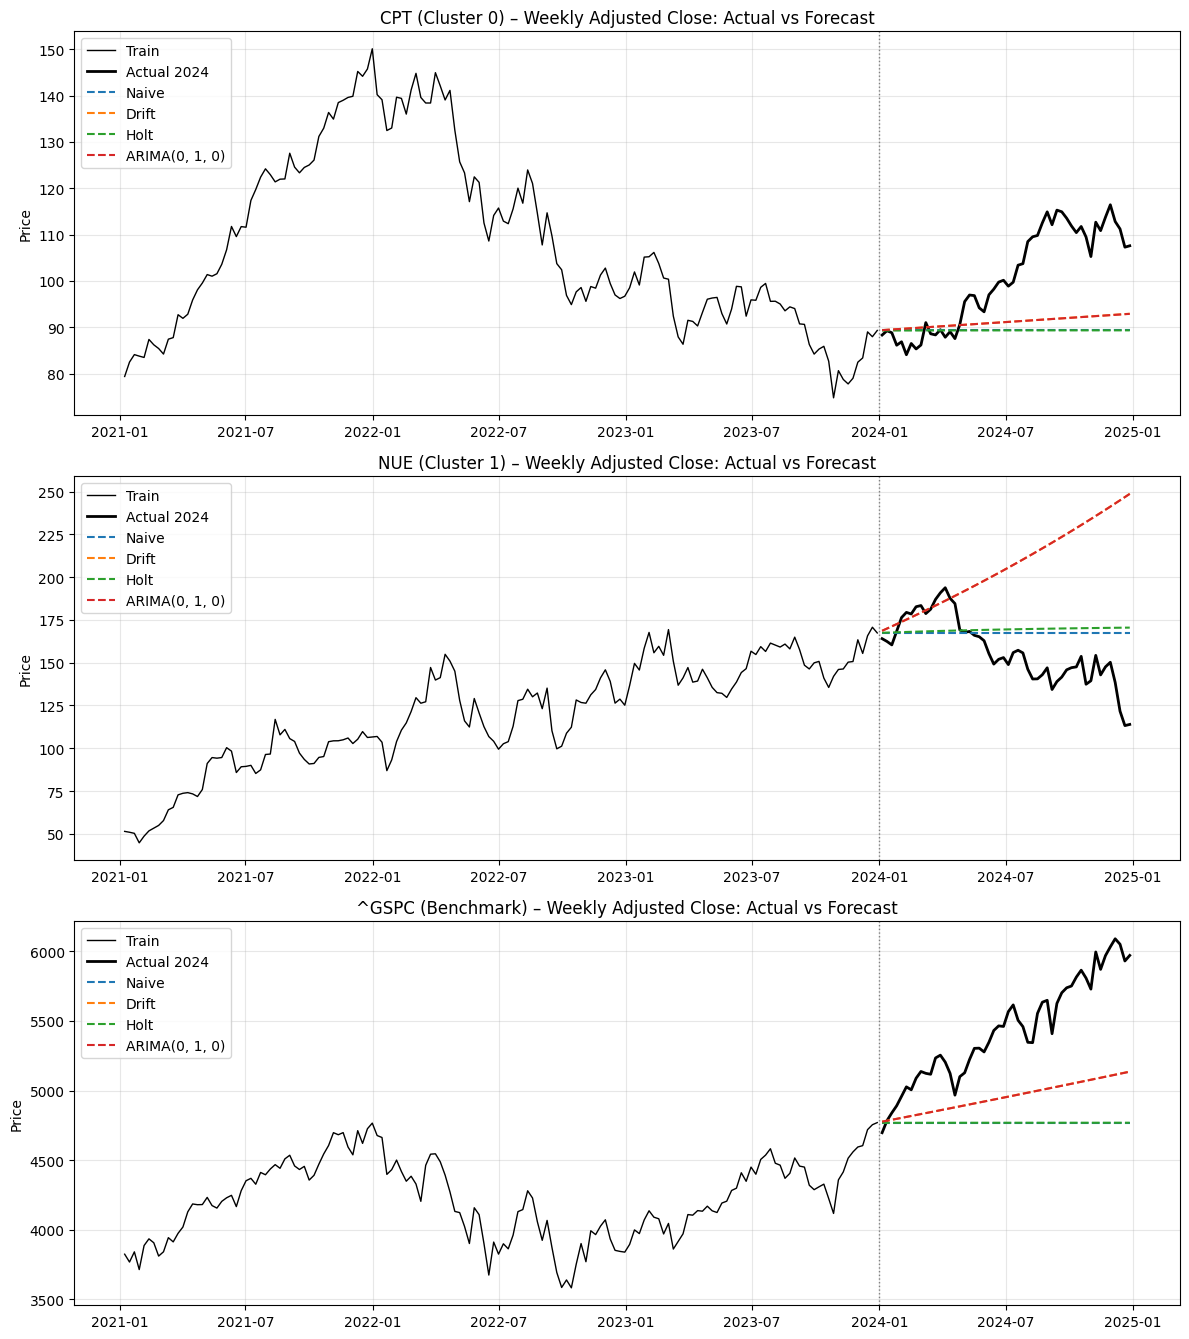

In [ ]:
# Actual vs forecast plots
n = len(forecast_series)

fig, axes = plt.subplots(n, 1, figsize=(12, 4.5 * n), squeeze=False)

for ax, (name, prices) in zip(axes[:, 0], forecast_series.items()):

    train, test = split_series(prices)
    output = forecast_outputs[name]

    ax.plot(train.index, train, color="black", linewidth=1, label="Train")
    ax.plot(test.index, test, color="black", linewidth=2, label="Actual 2024")

    for model_name in output.columns.drop("Actual"):
        ax.plot(output.index, output[model_name], linestyle="--", label=model_name)

    ax.axvline(TRAIN_END, color="grey", linestyle=":", linewidth=1)
    ax.set_title(f"{name} – Weekly Adjusted Close: Actual vs Forecast")
    ax.set_ylabel("Price")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{TASK_3_DIR}/forecast_comparison.png", dpi=160)
plt.show()

In [ ]:
print("Forecast accuracy on 2024 (lower is better):")
display(forecast_results.round(3))

# Best model per series by RMSE
best_models = forecast_results.loc[
    forecast_results.groupby("Series")["RMSE"].idxmin(),
    ["Series", "Model", "MAE", "RMSE", "MAPE_%"]
].set_index("Series")

print("\nBest model per series (lowest RMSE):")
display(best_models.round(3))

forecast_results.to_csv(f"{TASK_3_DIR}/forecast_accuracy.csv", index=False)
best_models.to_csv(f"{TASK_3_DIR}/best_model_per_series.csv")

Forecast accuracy on 2024 (lower is better):


,Series,Model,MAE,RMSE,MAPE_%
0,CPT (Cluster 0),Naive,12.212,15.340,11.334
1,CPT (Cluster 0),Drift,10.711,13.372,9.970
2,CPT (Cluster 0),Holt,12.198,15.325,11.320
3,CPT (Cluster 0),"ARIMA(0, 1, 0)",10.721,13.385,9.979
4,NUE (Cluster 1),Naive,17.923,21.498,12.291
5,NUE (Cluster 1),Drift,50.362,63.677,35.496
6,NUE (Cluster 1),Holt,19.266,23.065,13.267
7,NUE (Cluster 1),"ARIMA(0, 1, 0)",50.335,63.643,35.477
8,^GSPC (Benchmark),Naive,666.055,756.454,11.871
9,^GSPC (Benchmark),Drift,481.652,546.025,8.589



Best model per series (lowest RMSE):


,Model,MAE,RMSE,MAPE_%
Series,,,,
CPT (Cluster 0),Drift,10.711,13.372,9.970
NUE (Cluster 1),Naive,17.923,21.498,12.291
^GSPC (Benchmark),Drift,481.652,546.025,8.589


In [ ]:
diagnostics = []

for name, (order, fit) in arima_fits.items():

    residuals = fit.resid.iloc[1:]   # first residual is affected by differencing

    lb = acorr_ljungbox(residuals, lags=[10], return_df=True)

    diagnostics.append({
        "Series": name,
        "ARIMA_Order": str(order),
        "AIC": fit.aic,
        "LjungBox_Stat_lag10": lb["lb_stat"].iloc[0],
        "LjungBox_p_value": lb["lb_pvalue"].iloc[0],
        "Residuals_White_Noise": lb["lb_pvalue"].iloc[0] > 0.05
    })

diagnostics = pd.DataFrame(diagnostics)

print("ARIMA residual diagnostics:")
display(diagnostics.round(4))

diagnostics.to_csv(f"{TASK_3_DIR}/arima_diagnostics.csv", index=False)

print("\nTask 3 completed. Files saved in:", TASK_3_DIR)

ARIMA residual diagnostics:


,Series,ARIMA_Order,AIC,LjungBox_Stat_lag10,LjungBox_p_value,Residuals_White_Noise
0,CPT (Cluster 0),"(0, 1, 0)",-617.1674,5.1488,0.8810,True
1,NUE (Cluster 1),"(0, 1, 0)",-417.5011,8.3607,0.5937,True
2,^GSPC (Benchmark),"(0, 1, 0)",-718.5741,8.8258,0.5487,True



Task 3 completed. Files saved in: CRM_Coursework_Data/Task_3
